# Cross-size subliminal learning (bear) — `20260907_xsize-bear_mixed`

End-to-end analysis of the **completed** cross-size on-policy GKD campaign on the
three seed-0 PolyPythia bases at `step143000` — `pythia-{70m, 160m, 410m}`.
Bear only. Behaviour-only (no CKA / geometry / probes). Frozen teacher recipe
`ep5_lr5e-5_r128a128`; student recipe `lmb1.0_b1.0_lora_lr{2e-4,4e-4,8e-4}_e1_r8a16`
(λ=1, β=1 JSD, LoRA r8a16, 1 epoch, 625 steps, effective batch 32 at every size).

**The question.** The bear checkpoint grid (`20260828_ckptgrid-bear_160m`) measured
subliminal transfer between models of the *same shape*. This campaign asks whether
transfer survives a **shape mismatch** — teacher and student of different width and
depth — on a **shared seed-0 pretraining batch stream** (P0 gate G-c). Cross-size
cells are therefore "different init by construction, same stream": there is no
stream confound to explain away a null.

This notebook is **read-only** on cached `results/` + `logs/`. It does **not**
retrain, does **not** re-run bootstraps, and does **not** write anything under
`output_root`. Paths resolve from `configs/paths/paths_local.yaml` via
`analysis.setup.bootstrap`.

Pre-registration: `docs/PREREG_XSIZE.md` (X0–X4, filed before any student eval was
read). Constants: `subliminal_learning.campaign.xsize_plan`. Claim math:
`subliminal_learning.campaign.xsize_metrics`. Writer:
`pipelines/xsize_results_pipeline.py`. Plan:
`.claude/plans/cross-size_polypythia_campaign_9c4e1f27.plan.md`.

**How to run**
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/gkd_xsize_bear.ipynb` and run all cells top-to-bottom.

---

### Headline caveat — read this before any figure

The campaign **executed completely**: 180 of 180 planned student leaves and 13 of
13 teachers finished, every phase at its planned count. Nothing is unrun.

But **75 of 180 leaves (41.7%) were quarantined** by the pre-registered capability
guard (`perplexity_ratio > 5.0`), and the loss is not spread evenly — it is almost
entirely the **70M student**, every one of whose 60 leaves blew up, *including its
own student-base control*. The consequence is that the intended 3×3 matrix is, in
practice, a **2×2 over {160m, 410m} plus a single 70m→410m cell**: 5 of 9 cells
have surviving leaves. Three of the six cross pairs are **void** (no data), not
null (measured zero). §3 quantifies exactly what survived; every later figure is
restricted to what did.

---

### Reading guide (aggregation and sign rules)

- `Δ = p_target − matched control mean`, a difference of two probabilities, so
  theoretically (−1, 1). `0` = no subliminal transfer above the control.
  **Positive = the bear trait moved from teacher to student.**
- Two controls, never mixed. `Δ_sb` subtracts the **student-base** control
  (untuned `S → S`); `Δ_tb` subtracts the **teacher-base** control (untuned
  `T → S`), which absorbs what distilling from a different-size *untuned* model
  does to the student. `delta_primary` is `Δ_tb` on cross cells and `Δ_sb` on
  anchors. A missing matched control **raises** in the pipeline — it never falls
  back to the other control.
- **`xsize_cells.csv` rows are already means over leaves** (`n` = surviving
  leaves, 9 or 3 here). Never re-average them as if they were leaves. Use
  `xsize_delta.csv` (`level` = leaf) when you need per-leaf spread.
- **`xsize_delta.csv` still contains quarantined leaves** (15 of 78, flagged
  `quarantined=True`). Every aggregate in this notebook applies
  `~df.quarantined` first, matching what the pipeline did. Aggregating that file
  raw will *not* reproduce `xsize_cells.csv`.
- **Column order flips between files**: `xsize_leaves.csv` / `xsize_delta.csv`
  are `animal, student, teacher, …`; `xsize_cells.csv` is
  `animal, teacher, student, …`. Never use positional access.
- **`perplexity_ratio` is config-level, not per-gseed** — it is joined on keys
  that exclude `gseed`, so all three gseeds of one config carry the same value.
  This matters for X4 (see the cheat-sheet).
- No silent NaN fills. A cell with no surviving leaves is **absent**, and is drawn
  as an explicitly labelled grey "no surviving leaves" tile — never as 0.
- The join with the bear checkpoint grid is **descriptive only** (different code
  pin), as G9 was.
- Each figure is followed by a **Reading this figure** cell stating the question
  answered and the conclusion drawn from the rendered output. Final claims are in
  **§12**.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Inventory & coverage vs plan |
| 1 | Provenance: gates, LR picks, code pin, the pre-registered amendment |
| 2 | Fig1 — teacher acquisition and admission by size |
| 3 | Fig2 — capability-quarantine survival map (**what the campaign actually measured**) |
| 4 | Fig3 — the headline teacher-size × student-size matrix |
| 5 | Fig4 — X0 existence: per-pair cross-size transfer vs the 0.02 bar |
| 6 | Fig5 — X1 shape penalty against the student's own anchor |
| 7 | Fig6 — X2 direction asymmetry (small→large vs large→small) |
| 8 | X2 additive fit (**table only — the fit is degenerate**) |
| 9 | Fig7 — X3 learning-rate robustness |
| 10 | Fig8 — X4 capability coupling and where the quarantine cut |
| 11 | Fig9 — concordance with the same-shape bear checkpoint grid |
| 12 | Claims board X0–X4 + takeaways (recomputed from frames) |
| 13 | Limitations and how to extend |

### Explicit exclusions

- No stream arm (`-seed1` teachers), no cat arm, no storytelling eval, no forward
  KL, no CKA / geometry / probes / weight-space. All deferred (prereg §11).
- `14m` / `31m` bases (softmax-bottleneck regime) and every `-seed{N}` /
  `160m-{data,weight}-seed*` repo are out of scope.
- Width-only vs depth-only decomposition is **impossible here**: PolyPythia width
  and depth co-vary (both roughly double per size step, head dim fixed at 64), so
  "shape" in this notebook means the two together, never one of them.

### Metric cheat-sheet

Formulas match `xsize_metrics` and prereg §5–§6. Ranges are theoretical, not this
run's numbers (those print from the CSVs below).

| Name | Answers | Values | Calculation | Notes |
|---|---|---|---|---|
| `delta_sb` | Did GKD raise bear preference above an untuned **student-base** teacher? | (−1, 1) | `p_target − mean sb-control p_target`, matched on `(animal, student, lr, gseed)`. | Primary Δ for anchors and for the LR pick. |
| `delta_tb` | …above an untuned **teacher-base** model of the *teacher's* size? | (−1, 1) | `p_target − mean tb-control p_target`, matched on `(animal, student, teacher, lr, gseed)`. On anchors it is *defined* equal to `delta_sb`. | Primary Δ for cross cells: isolates the trait from the capability/prior shift of distilling from another size. |
| `penalty` | How much transfer does shape mismatch cost, in absolute Δ? | Same units as Δ | **`delta_anchor_s − delta_tb`** — the student's own same-shape anchor minus the cross cell. Positive = mismatch costs transfer. | **Deviation from the plan text**, which described `1 − ratio`. The CSV column is a *difference*, not a ratio. CI is a leaf-level two-sample bootstrap. |
| `rho_s` / `rho_t` | Same, expressed as a retained fraction. | Unbounded; NaN if the anchor is ≤ 0 or missing | `delta_tb / delta_anchor_s` and `delta_tb / delta_anchor_t`. `rho_t` uses the **teacher's** anchor at `lr*(T)`. | `1.0` = cross matches the anchor. `0` = mismatch wipes transfer. |
| `efficiency` | Is a weak cross result just a weak teacher? | Unbounded; NaN if the dose is 0/missing | `delta_tb / teacher_p_target`, where the dose is the mean `p_target` of **admitted** teachers of that size at the gate's tag. | Guards X1: a 70M teacher that barely learned bear must not be read as a shape penalty. |
| `iota` (ι) | Does direction matter? | (−2, 2) | `Δ_tb(small→large) − Δ_tb(large→small)`, per unordered size pair. `iota_dose` divides each side by its teacher's dose first. | `size_lo` is the **smaller** model. Positive ι = small→large wins. |
| `tau` / `sigma` | Is the matrix separable into emissivity × receptivity? | Δ units | OLS `Δ_ij = τ_i + σ_j` over the surviving 3×3 cells, identified by `mean(σ) = 0`. | τ = teacher-side emissivity, σ = student-side receptivity. **Needs ≥ 6 cells to be identified; see §8.** |
| `perplexity_ratio` | Did GKD wreck the student's Pile perplexity? | (0, ∞); `1` = unchanged | Student held-out Pile PPL / its **own base's** PPL. | Leaf quarantine bound is `> 5.0`. Config-level, not per-gseed. |
| `retained_fraction` | Does Δ survive residualising on capability loss? | Unbounded, uses absolute values | `|mean(Δ − β·(ppl − 1))| / |mean Δ|` with β an OLS slope per `(T, S, lr)` group. | X4's headline. **Unstable here** — when a group has one config the regressor is constant, β is forced to `0.0`, and `retained` is exactly `1.0` by construction, not by evidence. |

## Setup

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.campaign import xsize_plan as plan
from subliminal_learning.gkd.layout import GKD_STUDENTS_SUBDIR
from subliminal_learning.sdf.layout import SDF_TEACHERS_SUBDIR

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)

SIZES = list(plan.SIZES)                      # ("70m", "160m", "410m"), ascending
PARAMS_M = {"70m": 70.4, "160m": 162.0, "410m": 405.0}
D_MODEL = {"70m": 512, "160m": 768, "410m": 1024}
N_LAYERS = {"70m": 6, "160m": 12, "410m": 24}
palette = {"70m": "tab:blue", "160m": "tab:orange", "410m": "tab:green"}

TREE = OUTPUT_ROOT / GKD_STUDENTS_SUBDIR / plan.RUN_SET_ID
RES = TREE / "results"
LOGS = TREE / "logs"
TEACHER_TREE = OUTPUT_ROOT / SDF_TEACHERS_SUBDIR / plan.TEACHER_RUN_SET_ID

assert TREE.exists(), f"missing behaviour tree: {TREE}"
assert RES.exists(), f"missing results/: {RES}"
assert LOGS.exists(), f"missing logs/: {LOGS}"
assert "/mnt/ssd-1/" not in str(OUTPUT_ROOT), (
    f"refusing slow SSD-1 output_root: {OUTPUT_ROOT}"
)
if TREE.is_symlink():
    print("NOTE: TREE is a symlink ->", TREE.resolve())

print("ROOT           :", ROOT)
print("OUTPUT_ROOT    :", OUTPUT_ROOT)
print("TREE           :", TREE)
print("RUN_SET        :", plan.RUN_SET_ID)
print("sizes          :", SIZES, "(ascending; width and depth co-vary)")
print("animals        :", plan.ANIMALS)
print("teacher tag    :", plan.TEACHER_PARAM_TAG, "| fallbacks:", plan.TEACHER_FALLBACK_TAGS)
print("LR ladder      :", plan.LR_LADDER, "| default:", plan.LR_DEFAULT)
print("primary endpoint:", plan.PRIMARY_PROMPT_SET, "/", plan.PRIMARY_SCORING)
print("bootstrap      :", plan.BOOTSTRAP_N, "resamples over leaves, seed", plan.BOOTSTRAP_SEED)
print("quarantine     : ppl_ratio >", plan.QUARANTINE_PPL_RATIO_MAX,
      "or filter_drop >", plan.QUARANTINE_FILTER_DROP_MAX)
print("claim bars     : X0 min Δ", plan.X0_MIN_DELTA,
      "| X2 R2", plan.X2_ADDITIVE_R2_MIN, "/ |iota|", plan.X2_ASYM_MIN,
      "| X4 retained", plan.X4_RETAINED_FRACTION_MIN)


def scope(df: pd.DataFrame, note: str = "") -> None:
    """Print a compact SCOPE line for whatever key columns the frame has."""
    bits = [f"n={len(df)}"]
    for col in ("animal", "teacher", "student", "kind", "phase", "arm",
                "lr", "ftseed", "gseed", "direction", "shape_steps"):
        if col in df.columns:
            bits.append(f"{col}={df[col].nunique(dropna=False)}")
    line = "SCOPE: " + " | ".join(bits)
    if note:
        line += f" | {note}"
    print(line)


def live(df: pd.DataFrame) -> pd.DataFrame:
    """Non-quarantined rows only — what every pipeline aggregate was built from."""
    return df.loc[~df["quarantined"].astype(bool)].copy()


def pair_label(teacher: str, student: str) -> str:
    return f"{teacher}→{student}"


def fmt(value, nd: int = 3) -> str:
    """Round for an in-figure label; pass non-numerics through."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return str(value)
    return "n/a" if not np.isfinite(v) else f"{v:.{nd}f}"


def fmt_ci(lo, hi, nd: int = 3) -> str:
    return f"[{fmt(lo, nd)}, {fmt(hi, nd)}]"

NOTE: TREE is a symlink -> /mnt/cold-1/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260907_xsize-bear_mixed
ROOT           : /home/vishesh/eleutherAI/EleutherAI_subliminal_learning
OUTPUT_ROOT    : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning
TREE           : /mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260907_xsize-bear_mixed
RUN_SET        : 20260907_xsize-bear_mixed
sizes          : ['70m', '160m', '410m'] (ascending; width and depth co-vary)
animals        : ('bear',)
teacher tag    : ep5_lr5e-5_r128a128 | fallbacks: ('ep5_lr1e-4_r128a128', 'ep10_lr5e-5_r128a128')
LR ladder      : (0.0002, 0.0004, 0.0008) | default: 0.0004
primary endpoint: test / prob
bootstrap      : 10000 resamples over leaves, seed 20260907
quarantine     : ppl_ratio > 5.0 or filter_drop > 0.5
claim bars     : X0 min Δ 0.02 | X2 R2 0.85 / |iota| 0.05 | X4 retained 0.5


## Load artifacts

The twelve `plan.RESULTS_*` CSVs, `claims.json`, and the five `logs/` JSONs.
Fail loud if any required file is missing.

In [2]:
def _read_csv(name: str) -> pd.DataFrame:
    path = RES / name
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)


def _read_json(dirpath: Path, name: str) -> dict:
    path = dirpath / name
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text())


RESULT_FILES = (
    plan.RESULTS_LEAVES_CSV,
    plan.RESULTS_DELTA_CSV,
    plan.RESULTS_CELLS_CSV,
    plan.RESULTS_PENALTY_CSV,
    plan.RESULTS_ASYMMETRY_CSV,
    plan.RESULTS_ADDITIVE_FIT_CSV,
    plan.RESULTS_LR_CSV,
    plan.RESULTS_PPL_CSV,
    plan.RESULTS_BASE_PRIORS_CSV,
    plan.RESULTS_TEACHER_ADMISSION_CSV,
    plan.RESULTS_QUARANTINE_CSV,
    plan.RESULTS_GRID_CONCORDANCE_CSV,
    plan.RESULTS_CLAIMS_JSON,
)
for name in RESULT_FILES:
    assert (RES / name).exists(), f"missing {RES / name}"

LEAVES = _read_csv(plan.RESULTS_LEAVES_CSV)
DELTA = _read_csv(plan.RESULTS_DELTA_CSV)
CELLS = _read_csv(plan.RESULTS_CELLS_CSV)
PENALTY = _read_csv(plan.RESULTS_PENALTY_CSV)
ASYM = _read_csv(plan.RESULTS_ASYMMETRY_CSV)
ADDITIVE = _read_csv(plan.RESULTS_ADDITIVE_FIT_CSV)
LR = _read_csv(plan.RESULTS_LR_CSV)
PPL = _read_csv(plan.RESULTS_PPL_CSV)
BASE_PRIORS = _read_csv(plan.RESULTS_BASE_PRIORS_CSV)
ADMISSION = _read_csv(plan.RESULTS_TEACHER_ADMISSION_CSV)
QUAR = _read_csv(plan.RESULTS_QUARANTINE_CSV)
CONCORD = _read_csv(plan.RESULTS_GRID_CONCORDANCE_CSV)
CLAIMS = _read_json(RES, plan.RESULTS_CLAIMS_JSON)

STATE = _read_json(LOGS, plan.CAMPAIGN_STATE_FILE)
PICKS = _read_json(LOGS, plan.SCREEN_PICKS)
GATE = _read_json(LOGS, plan.TEACHER_GATE_REPORT)
PREFLIGHT = _read_json(LOGS, plan.PREFLIGHT_REPORT)
P0 = _read_json(LOGS, plan.P0_GATES_REPORT)
RUN_SET = json.loads((TREE / "run_set.json").read_text())

DONE_TEXT = (LOGS / plan.CAMPAIGN_DONE_FILE).read_text().strip()
print("CAMPAIGN_DONE:", DONE_TEXT)

# lr*(S), read from the persisted pick — never recomputed (prereg section 7).
LR_STAR = {size: float(rec["lr"]) for size, rec in PICKS["picks"].items()}
LR_FLAGGED = {size: bool(rec["flagged"]) for size, rec in PICKS["picks"].items()}
print("lr*(S)         :", LR_STAR)
print("pick flagged   :", LR_FLAGGED)

print("\nresolved results/ files:")
for path in sorted(RES.iterdir()):
    if path.is_file():
        print(f"  {path.name:28s} {path.stat().st_size:8d} B")

CAMPAIGN_DONE: campaign 20260907_xsize-bear_mixed finished 2026-09-07T07:42:20Z
lr*(S)         : {'70m': 0.0004, '160m': 0.0004, '410m': 0.0004}
pick flagged   : {'70m': True, '160m': True, '410m': False}

resolved results/ files:
  base_priors.csv                   339 B
  claims.json                      2590 B
  grid_concordance.csv              232 B
  teacher_admission.csv            1292 B
  xsize_additive_fit.csv            637 B
  xsize_asymmetry.csv               195 B
  xsize_cells.csv                  2078 B
  xsize_delta.csv                 20087 B
  xsize_leaves.csv                24976 B
  xsize_lr.csv                      299 B
  xsize_penalty.csv                 778 B
  xsize_ppl.csv                     958 B
  xsize_quarantine.csv            11227 B


## 0. Inventory & coverage vs plan

**What this measures.** Did the campaign actually run everything it planned?
Disk vs prereg §4: 117 treatments (27 P2 + 72 P3 + 18 P3b), 63 controls
(27 student-base + 36 teacher-base), 180 student leaves, 13 teachers. Also the
per-cell replication depth (9 leaves = 3 teacher-ftseeds × 3 gseeds at `lr*`,
3 leaves = ftseed 0 × 3 gseeds on the off-pick ladder rungs) and the split of
what survived the capability quarantine. Fail loud if the primary frame is empty.

In [3]:
if LEAVES.empty or DELTA.empty:
    raise RuntimeError("leaf/delta frames are empty - cannot score X0-X4")

scope(LEAVES, "all student leaves (treatments + controls)")
scope(DELTA, "treatment leaves carrying a delta")

EXPECTED = {
    "treatment": 117, "sb_control": 27, "tb_control": 36,
    "p2": 27, "p3": 72, "p3b": 18, "leaves": 180, "teachers": 13,
}
kind_counts = LEAVES["kind"].value_counts().to_dict()
phase_counts = LEAVES["phase"].value_counts(dropna=True).to_dict()

rows = [
    ("student leaves (total)", len(LEAVES), EXPECTED["leaves"]),
    ("treatments", kind_counts.get("treatment", 0), EXPECTED["treatment"]),
    ("student-base controls", kind_counts.get("sb_control", 0), EXPECTED["sb_control"]),
    ("teacher-base controls", kind_counts.get("tb_control", 0), EXPECTED["tb_control"]),
    ("P2 anchor-ladder treatments", phase_counts.get("p2", 0), EXPECTED["p2"]),
    ("P3 headline treatments", phase_counts.get("p3", 0), EXPECTED["p3"]),
    ("P3b off-pick-LR treatments", phase_counts.get("p3b", 0), EXPECTED["p3b"]),
    ("teacher leaves evaluated", len(ADMISSION), EXPECTED["teachers"]),
]
inv = pd.DataFrame(rows, columns=["item", "on_disk", "planned"])
inv["complete"] = inv["on_disk"] == inv["planned"]
display(inv)
if not inv["complete"].all():
    print("WARNING: coverage differs from plan - check the rows above")
else:
    print("Coverage: every planned leaf and teacher is on disk. Nothing is unrun.")

# `phase` and `ftseed` are NaN on controls by construction, not data loss.
n_ctrl = int((LEAVES["kind"] != "treatment").sum())
assert int(LEAVES["phase"].isna().sum()) == n_ctrl
assert int(LEAVES["ftseed"].isna().sum()) == n_ctrl
print(f"\nstructural NaNs: phase/ftseed empty on all {n_ctrl} control leaves (by design)")

n_quar = int(LEAVES["quarantined"].sum())
print(f"\nquarantined: {n_quar}/{len(LEAVES)} leaves "
      f"({100 * n_quar / len(LEAVES):.1f}%) - reasons:")
display(QUAR["quarantine_reason"].value_counts().rename("leaves").to_frame())

kept_max = live(LEAVES)["perplexity_ratio"].max()
quar_min = LEAVES.loc[LEAVES["quarantined"], "perplexity_ratio"].min()
print(f"empirical quarantine cut: max kept perplexity_ratio {kept_max:.4f} "
      f"< bound {plan.QUARANTINE_PPL_RATIO_MAX} <= min quarantined {quar_min:.4f}")

print("\nsurviving cells in xsize_cells.csv (already leaf-means):")
display(CELLS[["teacher", "student", "lr", "arm", "n", "mean_delta_primary"]])
print(f"cells: {len(CELLS)} | leaves folded in: {int(CELLS['n'].sum())} "
      f"| live delta rows: {len(live(DELTA))}  (must match)")
assert int(CELLS["n"].sum()) == len(live(DELTA))

SCOPE: n=180 | animal=1 | teacher=3 | student=3 | kind=3 | phase=4 | lr=3 | ftseed=4 | gseed=3 | all student leaves (treatments + controls)
SCOPE: n=78 | animal=1 | teacher=3 | student=2 | kind=1 | phase=3 | arm=2 | lr=3 | ftseed=3 | gseed=3 | direction=3 | shape_steps=3 | treatment leaves carrying a delta


,item,on_disk,planned,complete
0,student leaves (total),180,180,True
1,treatments,117,117,True
2,student-base controls,27,27,True
3,teacher-base controls,36,36,True
4,P2 anchor-ladder treatments,27,27,True
5,P3 headline treatments,72,72,True
6,P3b off-pick-LR treatments,18,18,True
7,teacher leaves evaluated,13,13,True


Coverage: every planned leaf and teacher is on disk. Nothing is unrun.

structural NaNs: phase/ftseed empty on all 63 control leaves (by design)

quarantined: 75/180 leaves (41.7%) - reasons:


,leaves
quarantine_reason,
ppl_ratio,75


empirical quarantine cut: max kept perplexity_ratio 4.8788 < bound 5.0 <= min quarantined 5.0366

surviving cells in xsize_cells.csv (already leaf-means):


,teacher,student,lr,arm,n,mean_delta_primary
0,160m,160m,0.0002,anchor,3,0.195613
1,160m,160m,0.0004,anchor,9,0.355994
2,160m,410m,0.0004,cross,9,0.369560
3,410m,160m,0.0002,cross,3,0.008338
4,410m,160m,0.0004,cross,9,0.015601
5,410m,160m,0.0008,cross,3,0.007709
6,410m,410m,0.0002,anchor,3,0.404205
7,410m,410m,0.0004,anchor,9,0.372939
8,410m,410m,0.0008,anchor,3,0.396550
9,70m,160m,0.0002,cross,3,0.009942


cells: 11 | leaves folded in: 63 | live delta rows: 63  (must match)


## 1. Provenance: gates, LR picks, code pin, and the pre-registered amendment

**What this measures.** The decisions that were frozen *before* results were read,
and the one threshold that was amended mid-campaign. Three things matter for
trusting every number below:

1. **P0 gate G-c** — do the three bases share one pretraining batch stream? If not,
   every cross-size cell is confounded by stream, not shape.
2. **Teacher gate** — which tag each size teaches at, and how many leaves were
   admitted.
3. **The amendment** — the teacher perplexity bound was raised `2.0 → 3.0` after P1
   and *before any student eval was read*, on teacher evidence only. The run-set
   `sha_advances` entry records it. Without it the entire 70M teacher row would
   have been voided a priori. This is disclosed, not hidden: X4 measures the
   capability axis per leaf rather than assuming it.

In [4]:
print("=== P0 gates (shared-stream evidence) ===")
print("passed:", P0.get("passed"))
for key in ("g_a", "g_c", "checks", "gates"):
    if key in P0:
        print(f"  {key}: {json.dumps(P0[key])[:600]}")

print("\n=== teacher gate ===")
gate_rows = pd.DataFrame(GATE["decisions"]).T[
    ["size", "tag", "status", "n_admitted_frozen"]
]
display(gate_rows.loc[SIZES])
print("thresholds:", GATE["thresholds"])
print(f"NOTE: ppl_max in the report is {GATE['thresholds']['ppl_max']} "
      f"(= plan.TEACHER_PPL_RATIO_MAX {plan.TEACHER_PPL_RATIO_MAX}); "
      "amended from 2.0 - see the sha_advances entry below.")

print("\n=== LR picks (persisted once, never recomputed) ===")
pick_rows = []
for size, rec in PICKS["picks"].items():
    for entry in rec["table"]:
        pick_rows.append({
            "student": size, "lr": entry["lr"], "mean_delta_sb": entry["delta"],
            "mean_ppl_ratio": entry["ppl_ratio"],
            "passes_ppl_guard": entry["passes_guard"],
            "picked": entry["lr"] == rec["lr"],
            "pick_reason": rec["reason"], "flagged": rec["flagged"],
        })
picks_df = pd.DataFrame(pick_rows)
display(picks_df)
print("pick guard: mean leaf perplexity_ratio <=", PICKS["thresholds"]["ppl_ratio_max"],
      "| tie band", PICKS["thresholds"]["tie_band"],
      "| default", PICKS["thresholds"]["lr_default"])
for size in SIZES:
    rec = PICKS["picks"][size]
    flag = "FLAGGED - fell back to the default" if rec["flagged"] else "earned"
    print(f"  lr*({size}) = {rec['lr']:.0e}  [{rec['reason']}] {flag}")

print("\n=== code pin ===")
print("run_set git_sha:", RUN_SET.get("git_sha"))
for adv in RUN_SET.get("sha_advances", []):
    print(f"  advance {adv['from'][:8]} -> {adv['to'][:8]} at {adv['at']}")
    print(f"    reason: {adv['reason']}")

print("\n=== campaign state transitions ===")
transitions = STATE.get("transitions") or {}
for name in sorted(transitions):
    print(f"  {name}: {json.dumps(transitions[name])[:180]}")
print("\npreflight passed:", PREFLIGHT.get("passed"), "| prereg:", PREFLIGHT.get("prereg"))

=== P0 gates (shared-stream evidence) ===
passed: True

=== teacher gate ===


,size,tag,status,n_admitted_frozen
70m,70m,ep5_lr5e-5_r128a128,frozen,3
160m,160m,ep5_lr5e-5_r128a128,frozen,3
410m,410m,ep5_lr5e-5_r128a128,frozen,3


thresholds: {'sd_multiple': 5.0, 'abs_min': 0.02, 'ppl_max': 3.0, 'min_admitted_per_base': 2, 'frozen_tag': 'ep5_lr5e-5_r128a128', 'fallback_tags': ['ep5_lr1e-4_r128a128', 'ep10_lr5e-5_r128a128'], 'fallback_sizes': ['70m', '410m']}
NOTE: ppl_max in the report is 3.0 (= plan.TEACHER_PPL_RATIO_MAX 3.0); amended from 2.0 - see the sha_advances entry below.

=== LR picks (persisted once, never recomputed) ===


,student,lr,mean_delta_sb,mean_ppl_ratio,passes_ppl_guard,picked,pick_reason,flagged
0,70m,0.0002,0.012462,8.453282e+00,False,False,no_lr_passed_ppl_guard,True
1,70m,0.0004,0.059699,1.431948e+01,False,True,no_lr_passed_ppl_guard,True
2,70m,0.0008,0.060354,3.054436e+01,False,False,no_lr_passed_ppl_guard,True
3,160m,0.0002,0.195613,2.531616e+00,False,False,no_lr_passed_ppl_guard,True
4,160m,0.0004,0.295757,2.448951e+00,False,True,no_lr_passed_ppl_guard,True
5,160m,0.0008,0.109152,6.071909e+24,False,False,no_lr_passed_ppl_guard,True
6,410m,0.0002,0.404205,1.456444e+00,True,False,tie_band,False
7,410m,0.0004,0.429904,1.458118e+00,True,True,tie_band,False
8,410m,0.0008,0.396550,1.476663e+00,True,False,tie_band,False


pick guard: mean leaf perplexity_ratio <= 1.5 | tie band 0.02 | default 0.0004
  lr*(70m) = 4e-04  [no_lr_passed_ppl_guard] FLAGGED - fell back to the default
  lr*(160m) = 4e-04  [no_lr_passed_ppl_guard] FLAGGED - fell back to the default
  lr*(410m) = 4e-04  [tie_band] earned

=== code pin ===
run_set git_sha: 22cc3c8f27303e0cc7ca4e3fe550bc1830b2bea6
  advance 5fa3911b -> 22cc3c8f at 2026-09-07T00:25:02Z
    reason: P2->P3 gate config-dir fix, join dtype fix, quarantine propagation, TEACHER_PPL_RATIO_MAX 2.0->3.0

=== campaign state transitions ===
  finalize: {"at": "2026-09-07T07:42:20Z", "results": ["/mnt/ssd-3/soar-subliminal/vishesh/subliminal_learning/gkd_students/20260907_xsize-bear_mixed/results/xsize_leaves.csv", "/mnt/ssd-3/soa
  pick_lr_160m: {"at": "2026-09-07T00:26:40Z", "lr": 0.0004}
  pick_lr_410m: {"at": "2026-09-07T00:26:40Z", "lr": 0.0004}
  pick_lr_70m: {"at": "2026-09-07T00:26:40Z", "lr": 0.0004}
  preflight: {"at": "2026-09-06T18:51:15Z", "train_yamls": ["xsize_p

## 2. Fig1 — teacher acquisition and admission by base size

**What this measures.** Every size needs a teacher that actually acquired the bear
trait before "does it transfer across shapes?" is even a question. This plots each
of the 13 SDF teacher leaves' bear preference against its own untuned base prior,
coloured by the capability cost it paid (`perplexity_ratio`), with the admission
bound marked. It is the dose axis that X1's `efficiency` normalises against.

SCOPE: n=13 | ftseed=3 | teacher leaves
admitted: 12 / 13


,size,tag,ftseed,p_target,ppl_ratio,reason
1,70m,ep5_lr1e-4_r128a128,0,0.081278,3.023682,ppl_ratio(3.0237>3)


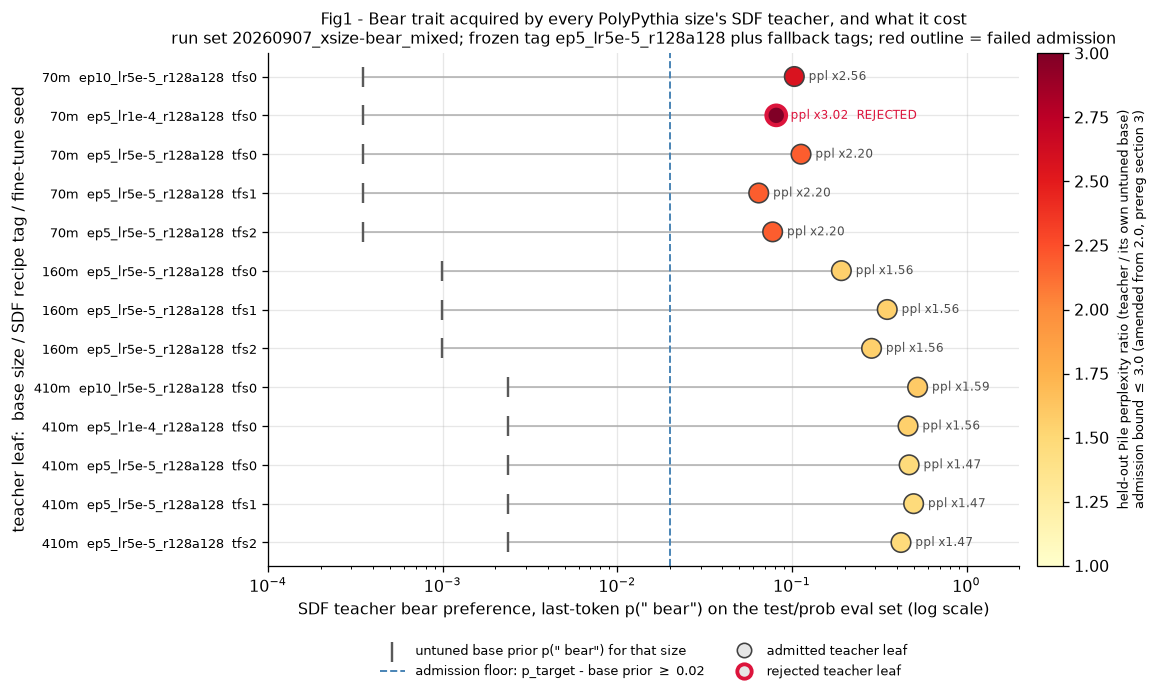


teacher dose (mean p_target of admitted frozen-tag leaves), used by X1 efficiency:
size
70m     0.0849
160m    0.2763
410m    0.4624

fold increase over the untuned base prior:
size
70m     244.2
160m    277.6
410m    196.2


In [5]:
adm = ADMISSION.copy()
adm["size"] = pd.Categorical(adm["size"], categories=SIZES, ordered=True)
adm = adm.sort_values(["size", "tag", "ftseed"]).reset_index(drop=True)
adm["label"] = (
    adm["size"].astype(str) + "  " + adm["tag"] + "  tfs" + adm["ftseed"].astype(int).astype(str)
)
scope(adm, "teacher leaves")
print("admitted:", int(adm["admitted"].sum()), "/", len(adm))
display(adm.loc[~adm["admitted"], ["size", "tag", "ftseed", "p_target", "ppl_ratio", "reason"]])

y = np.arange(len(adm))
fig, ax = plt.subplots(figsize=(10.4, 6.2))
norm = mpl.colors.Normalize(vmin=1.0, vmax=float(plan.TEACHER_PPL_RATIO_MAX))
sc = ax.scatter(
    adm["p_target"], y, c=adm["ppl_ratio"], cmap="YlOrRd", norm=norm,
    s=150, zorder=3, edgecolors=["0.25" if a else "crimson" for a in adm["admitted"]],
    linewidths=[1.0 if a else 2.6 for a in adm["admitted"]],
)
ax.scatter(
    adm["base_prior"], y, marker="|", s=170, color="0.35", zorder=3,
    label="untuned base prior p(\" bear\") for that size",
)
for i, row in adm.iterrows():
    ax.plot([row["base_prior"], row["p_target"]], [i, i], color="0.75", lw=1.2, zorder=1)
    ax.annotate(
        f"ppl x{row['ppl_ratio']:.2f}" + ("" if row["admitted"] else "  REJECTED"),
        (row["p_target"], i), xytext=(9, 0), textcoords="offset points",
        va="center", fontsize=7.5,
        color="crimson" if not row["admitted"] else "0.3",
    )
ax.axvline(plan.ADMISSION_ABS_MIN, color="steelblue", ls="--", lw=1.2,
           label=f"admission floor: p_target - base prior $\\geq$ {plan.ADMISSION_ABS_MIN}")
ax.set_xscale("log")
ax.set_xlim(1e-4, 2.0)
ax.set_yticks(y)
ax.set_yticklabels(adm["label"], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(
    "SDF teacher bear preference, last-token p(\" bear\") on the "
    f"{plan.PRIMARY_PROMPT_SET}/{plan.PRIMARY_SCORING} eval set (log scale)"
)
ax.set_ylabel("teacher leaf:  base size / SDF recipe tag / fine-tune seed")
ax.set_title(
    "Fig1 - Bear trait acquired by every PolyPythia size's SDF teacher, and what it cost\n"
    f"run set {plan.RUN_SET_ID}; frozen tag {plan.TEACHER_PARAM_TAG} plus fallback tags; "
    "red outline = failed admission",
    fontsize=10,
)
cbar = fig.colorbar(sc, ax=ax, pad=0.02)
cbar.set_label(
    "held-out Pile perplexity ratio (teacher / its own untuned base)\n"
    f"admission bound $\\leq$ {plan.TEACHER_PPL_RATIO_MAX} (amended from 2.0, prereg section 3)",
    fontsize=8,
)
handles = ax.get_legend_handles_labels()[0] + [
    Line2D([], [], marker="o", ls="none", mfc="0.9", mec="0.25", mew=1.0, ms=9,
           label="admitted teacher leaf"),
    Line2D([], [], marker="o", ls="none", mfc="0.9", mec="crimson", mew=2.4, ms=9,
           label="rejected teacher leaf"),
]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=2, fontsize=8, frameon=False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

dose = (
    adm.loc[adm["admitted"] & (adm["tag"] == plan.TEACHER_PARAM_TAG)]
    .groupby("size", observed=True)["p_target"].mean()
)
print("\nteacher dose (mean p_target of admitted frozen-tag leaves), used by X1 efficiency:")
print(dose.round(4).to_string())
print("\nfold increase over the untuned base prior:")
print((dose / adm.groupby("size", observed=True)["base_prior"].first()).round(1).to_string())

### Reading this figure

**Question answered:** Did every PolyPythia size acquire the bear trait as an SDF
teacher, and at what capability cost — i.e. is there a usable teacher on all three
rows of the 3×3?

**Conclusion from the plot:** Yes for all three sizes — every frozen-tag teacher
sits 2–3 orders of magnitude above its own base prior (70M 0.065–0.113 vs prior
0.00035; 160M 0.192–0.351; 410M 0.421–0.497) and 12 of 13 leaves are admitted —
but the trait scales strongly with size while the capability cost moves the other
way, so the 70M teacher is both the weakest (≈0.085 mean) and the most damaged
(perplexity ×2.20), and it is only admissible at all under the amended ×3.0 bound.

**Axes.** y = one row per teacher leaf (size / SDF tag / fine-tune seed).
x = teacher last-token p(" bear") on `test`/`prob`, log scale. The grey tick and
connecting line mark that size's untuned base prior, so the line length *is* the
acquired trait. Colour = `perplexity_ratio` against the amended ×3.0 admission
bound; red outline = rejected.

**How the metric is calculated.** `teacher_admission.csv`, one row per
`(size, tag, ftseed)`. `p_target` varies by fine-tune seed; `base_prior` and
`ppl_ratio` are constant per size and per `(size, tag)` respectively and are
repeated across seeds. Admission is `admit_teacher` in `xsize_selection.py`.
Note the 5·SD criterion is inert in this run — the pipeline passes `control_sd=None`,
so criterion 1 reduces to `p_target >= base_prior`; the binding tests are the 0.02
absolute floor and the perplexity bound.

## 3. Fig2 — capability-quarantine survival map

**What this measures.** This is the most important diagnostic in the notebook, and
it must be read *before* the headline matrix. The pre-registered guard quarantines
any leaf whose student perplexity ratio exceeds 5.0. It fired on 41.7% of leaves.
This map shows exactly which teacher→student cells kept enough leaves to be
scored, and which were wiped out — i.e. what the campaign is actually able to
answer, versus what it planned to answer.

treatment leaves kept / total, all learning rates pooled:


,student 70m,student 160m,student 410m
teacher 70m,0 / 15,3 / 15,9 / 9
teacher 160m,0 / 15,12 / 15,9 / 9
teacher 410m,0 / 9,15 / 15,15 / 15



control leaves by kind and student size (a dead control voids its treatments even when they survive):


kept  total
kind       student             
sb_control 160m        9      9
           410m        9      9
           70m         0      9
tb_control 160m       18     18
           410m        6      6
           70m         0     12

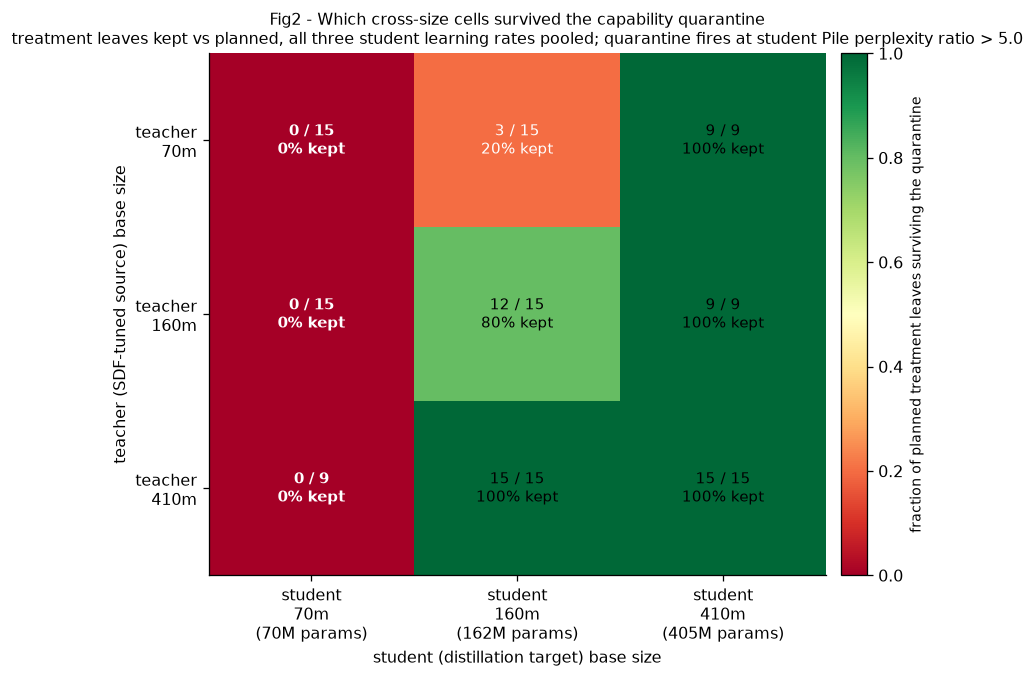


cells with zero surviving treatment leaves: 70m→70m, 160m→70m, 410m→70m
student sizes still scorable: ['160m', '410m']

quarantined leaves by student size (all kinds):
student
70m     60
160m    15
410m     0


In [6]:
treat = LEAVES.loc[LEAVES["kind"] == "treatment"]
tot = treat.pivot_table(index="teacher", columns="student", values="p_target", aggfunc="size")
kept = live(treat).pivot_table(index="teacher", columns="student", values="p_target", aggfunc="size")
tot = tot.reindex(index=SIZES, columns=SIZES).fillna(0).astype(int)
kept = kept.reindex(index=SIZES, columns=SIZES).fillna(0).astype(int)
frac = (kept / tot.replace(0, np.nan))

print("treatment leaves kept / total, all learning rates pooled:")
display(pd.DataFrame(
    kept.astype(str).to_numpy() + " / " + tot.astype(str).to_numpy(),
    index=[f"teacher {s}" for s in SIZES], columns=[f"student {s}" for s in SIZES],
))

ctrl = LEAVES.loc[LEAVES["kind"] != "treatment"]
ctrl_summary = (
    ctrl.assign(surviving=~ctrl["quarantined"].astype(bool))
    .groupby(["kind", "student"], observed=True)["surviving"]
    .agg(["sum", "size"]).rename(columns={"sum": "kept", "size": "total"})
)
print("\ncontrol leaves by kind and student size "
      "(a dead control voids its treatments even when they survive):")
display(ctrl_summary)

fig, ax = plt.subplots(figsize=(7.6, 6.0))
cmap = mpl.cm.RdYlGn.copy()
cmap.set_bad("0.85")
im = ax.imshow(np.ma.masked_invalid(frac.to_numpy()), cmap=cmap, vmin=0.0, vmax=1.0,
               origin="upper", aspect="auto")
for i, t in enumerate(SIZES):
    for j, s in enumerate(SIZES):
        k, n = int(kept.loc[t, s]), int(tot.loc[t, s])
        pct = "" if n == 0 else f"\n{100 * k / n:.0f}% kept"
        ax.text(j, i, f"{k} / {n}{pct}", ha="center", va="center", fontsize=9.5,
                color="black" if (n and k / n > 0.35) else "white",
                fontweight="bold" if k == 0 else "normal")
ax.set_xticks(range(3), [f"student\n{s}\n({PARAMS_M[s]:.0f}M params)" for s in SIZES])
ax.set_yticks(range(3), [f"teacher\n{s}" for s in SIZES])
ax.set_xlabel("student (distillation target) base size")
ax.set_ylabel("teacher (SDF-tuned source) base size")
ax.set_title(
    "Fig2 - Which cross-size cells survived the capability quarantine\n"
    f"treatment leaves kept vs planned, all three student learning rates pooled; "
    f"quarantine fires at student Pile perplexity ratio > {plan.QUARANTINE_PPL_RATIO_MAX}",
    fontsize=10,
)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label("fraction of planned treatment leaves surviving the quarantine", fontsize=8.5)
ax.grid(False)
plt.tight_layout()
plt.show()

dead = [(t, s) for t in SIZES for s in SIZES if tot.loc[t, s] > 0 and kept.loc[t, s] == 0]
print("\ncells with zero surviving treatment leaves:",
      ", ".join(pair_label(t, s) for t, s in dead) or "none")
print("student sizes still scorable:", sorted({s for t in SIZES for s in SIZES
                                               if kept.loc[t, s] > 0}, key=SIZES.index))
q_by_student = QUAR.groupby("student", observed=True).size().reindex(SIZES).fillna(0).astype(int)
print("\nquarantined leaves by student size (all kinds):")
print(q_by_student.to_string())

### Reading this figure

**Question answered:** After the pre-registered capability guard, which
teacher-size → student-size cells still have leaves to score — i.e. what can this
campaign actually measure?

**Conclusion from the plot:** The 70M **student** column is completely destroyed —
0 of 60 leaves survive across all three teachers and all three learning rates,
including its own student-base control — so the intended 3×3 collapses to a 2×2
over {160M, 410M} plus a partially-surviving 70M→160M cell; the 410M student
column is untouched (100% kept from every teacher), and damage is otherwise
concentrated where a small model is the *target*, not where it is the source.

**Axes.** Rows = teacher size, columns = student size. Colour and label = fraction
of that cell's planned treatment leaves that survived, with `kept / total` counts;
bold = wiped out. All three learning rates are pooled here to show the total
damage; §4 restricts to `lr*(S)`.

**How the metric is calculated.** `xsize_leaves.csv` filtered to
`kind == "treatment"`, grouped by `(teacher, student)`; "kept" is
`~quarantined` after `propagate_control_quarantine`. Quarantine is
`perplexity_ratio > 5.0` or `filter_drop > 0.5`; in this run **all 75 quarantined
leaves fired on `ppl_ratio` alone** — the filter-drop bound never triggered.

**What this does and does not license.** The three void X0 pairs in §5 are void
*because of this map*: 70M-student cells have no control to subtract and no
treatment to score. They are **not** measurements of zero transfer.

## 4. Fig3 — the headline teacher-size × student-size matrix

**What this measures.** The campaign's purpose: cell-mean subliminal Δ for every
ordered `teacher → student` pair at that student's picked learning rate. Diagonal
cells (anchors) use `Δ_sb`; off-diagonal (cross) cells use `Δ_tb`, which subtracts
an untuned teacher-base control of the *teacher's* size so the number isolates the
trait rather than the capability shift of distilling from another shape.

SCOPE: n=5 | animal=1 | teacher=3 | student=2 | arm=2 | lr=1 | direction=3 | shape_steps=3 | cells at lr*(S)


,teacher,student,arm,shape_steps,direction,n,mean_delta_primary,ci_low,ci_high,mean_ppl_ratio
1,160m,160m,anchor,0,same,9,0.355994,0.312398,0.401726,2.441651
2,160m,410m,cross,1,up,9,0.369560,0.323320,0.418800,1.802394
4,410m,160m,cross,1,down,9,0.015601,0.009868,0.022338,2.646545
7,410m,410m,anchor,0,same,9,0.372939,0.333186,0.413145,1.471710
10,70m,410m,cross,2,up,9,0.117600,0.097508,0.139629,3.305385


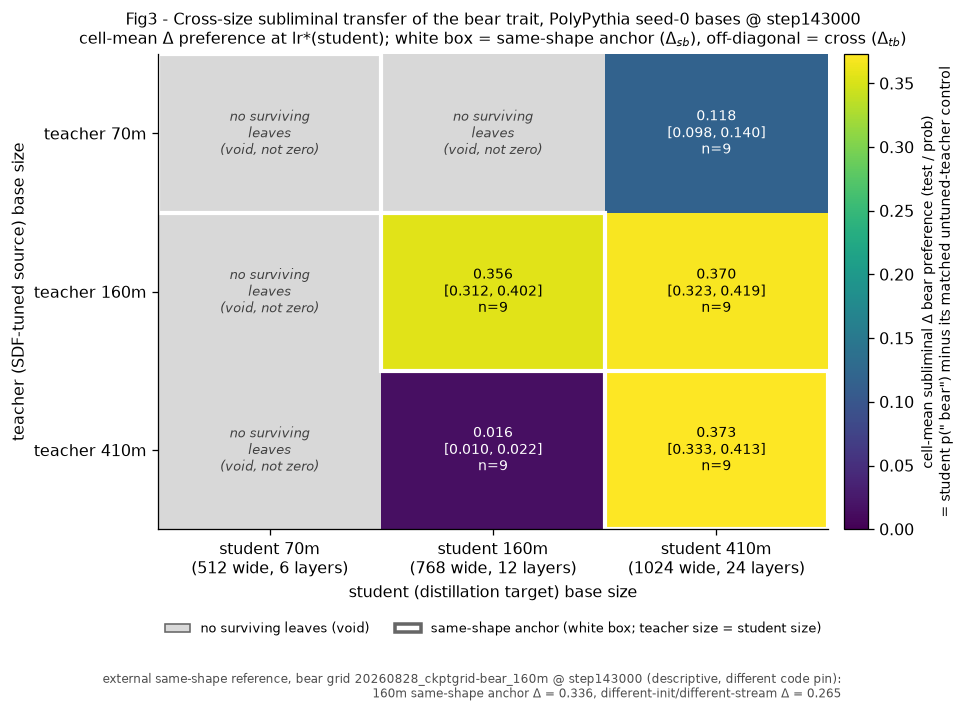


anchors (same shape) vs one-step cross cells at lr*(S):
  160m→160m      anchor shape_steps=0 same  delta=0.3560 [0.3124, 0.4017] n=9
  410m→410m      anchor shape_steps=0 same  delta=0.3729 [0.3332, 0.4131] n=9
  160m→410m      cross  shape_steps=1 up    delta=0.3696 [0.3233, 0.4188] n=9
  410m→160m      cross  shape_steps=1 down  delta=0.0156 [0.0099, 0.0223] n=9
  70m→410m       cross  shape_steps=2 up    delta=0.1176 [0.0975, 0.1396] n=9


In [7]:
star = CELLS.loc[[
    abs(row["lr"] - LR_STAR[row["student"]]) < 1e-12 for _, row in CELLS.iterrows()
]].copy()
scope(star, "cells at lr*(S)")
display(star[["teacher", "student", "arm", "shape_steps", "direction", "n",
              "mean_delta_primary", "ci_low", "ci_high", "mean_ppl_ratio"]])

mat = pd.DataFrame(np.nan, index=SIZES, columns=SIZES)
ann = pd.DataFrame("", index=SIZES, columns=SIZES)
for _, r in star.iterrows():
    mat.loc[r["teacher"], r["student"]] = r["mean_delta_primary"]
    ann.loc[r["teacher"], r["student"]] = (
        f"{r['mean_delta_primary']:.3f}\n{fmt_ci(r['ci_low'], r['ci_high'])}\nn={int(r['n'])}"
    )

fig, ax = plt.subplots(figsize=(8.6, 6.6))
cmap = mpl.cm.viridis.copy()
cmap.set_bad("0.85")
vmax = float(np.nanmax(mat.to_numpy()))
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy()), cmap=cmap, vmin=0.0, vmax=vmax,
               origin="upper", aspect="auto")
for i, t in enumerate(SIZES):
    for j, s in enumerate(SIZES):
        val = mat.loc[t, s]
        if np.isfinite(val):
            ax.text(j, i, ann.loc[t, s], ha="center", va="center", fontsize=8.5,
                    color="white" if val < 0.55 * vmax else "black")
        else:
            ax.text(j, i, "no surviving\nleaves\n(void, not zero)", ha="center",
                    va="center", fontsize=8, color="0.25", style="italic")
        if i == j:
            ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                               edgecolor="white", lw=2.6))
ax.set_xticks(range(3), [f"student {s}\n({D_MODEL[s]} wide, {N_LAYERS[s]} layers)" for s in SIZES])
ax.set_yticks(range(3), [f"teacher {s}" for s in SIZES])
ax.set_xlabel("student (distillation target) base size")
ax.set_ylabel("teacher (SDF-tuned source) base size")
ax.set_title(
    "Fig3 - Cross-size subliminal transfer of the bear trait, PolyPythia seed-0 bases @ step143000\n"
    "cell-mean $\\Delta$ preference at lr*(student); white box = same-shape anchor ($\\Delta_{sb}$), "
    "off-diagonal = cross ($\\Delta_{tb}$)",
    fontsize=10,
)
cbar = fig.colorbar(im, ax=ax, pad=0.02)
cbar.set_label(
    "cell-mean subliminal $\\Delta$ bear preference (test / prob)\n"
    "= student p(\" bear\") minus its matched untuned-teacher control",
    fontsize=8.5,
)
ref = plan.GRID_REFERENCE
ax.grid(False)
ax.legend(handles=[
    mpl.patches.Patch(facecolor="0.85", edgecolor="0.4", label="no surviving leaves (void)"),
    mpl.patches.Patch(facecolor="none", edgecolor="0.4", lw=2.2,
                      label="same-shape anchor (white box; teacher size = student size)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8, frameon=False)
ax.text(
    1.02, -0.30,
    f"external same-shape reference, bear grid {ref['run_set_id']} @ step{ref['step']} "
    f"(descriptive, different code pin):\n"
    f"160m same-shape anchor $\\Delta$ = {ref['anchor_delta']}, "
    f"different-init/different-stream $\\Delta$ = {ref['di_ds_delta']}",
    transform=ax.transAxes, ha="right", va="top", fontsize=7.5, color="0.3",
)
plt.tight_layout()
plt.show()

print("\nanchors (same shape) vs one-step cross cells at lr*(S):")
for _, r in star.sort_values(["arm", "teacher"]).iterrows():
    print(f"  {pair_label(r['teacher'], r['student']):14s} {r['arm']:6s} "
          f"shape_steps={int(r['shape_steps'])} {r['direction']:5s} "
          f"delta={r['mean_delta_primary']:.4f} {fmt_ci(r['ci_low'], r['ci_high'], 4)} "
          f"n={int(r['n'])}")

### Reading this figure

**Question answered:** Does the bear trait transfer between PolyPythia models of
different width and depth on a shared pretraining stream, and does the answer
depend on which side is bigger?

**Conclusion from the plot:** Cross-size transfer is real but violently
direction-dependent — into the 410M student it is essentially free (160M→410M
0.370, statistically indistinguishable from the 410M anchor 0.373, and even the
two-step 70M→410M reaches 0.118), while the reverse 410M→160M collapses to 0.016
against a 160M anchor of 0.356, i.e. about 4% of the same-shape result.

**Axes.** Rows = teacher size, columns = student size (annotated with `d_model`
and layer count, which co-vary in PolyPythia). Colour and label = cell-mean Δ with
its 95% bootstrap CI and surviving-leaf count `n`. White box = the same-shape
anchor on the diagonal. Grey = no surviving leaves.

**How the metric is calculated.** `xsize_cells.csv` rows filtered to
`lr == lr*(student)` from `screen_picks.json` — these are **already means over
leaves** (`n` = 9 at `lr*`), never re-averaged here. `mean_delta_primary` is
`Δ_sb` on anchors and `Δ_tb` on cross cells. CIs are 10 000-resample percentile
bootstraps over leaves, computed by the pipeline.

**What this does and does not license.** The 70M student column is grey because of
the quarantine in §3, not because transfer was measured and found absent. Only 5
of the 9 planned cells are readable, so no claim about 70M receptivity can be made
from this run in either direction.

## 5. Fig4 — X0 existence: per-pair cross-size transfer against the pre-registered bar

**What this measures.** X0 asks, per ordered cross pair, whether cell-mean `Δ_tb`
has a 95% CI that excludes 0 **and** a mean of at least 0.02. A pair is **void**
rather than failing when its teacher size had no admissible teacher, its matched
anchor is missing, or the anchor's own CI covers 0 — void means "not measurable
here", and is reported separately from a measured failure.

,pair,teacher,student,status,reason,mean,ci_low,ci_high,headline,shape_steps
0,160m→410m,160m,410m,holds,NaN,0.369560,0.323320,0.418800,True,1
1,160m→70m,160m,70m,void,missing_anchor,NaN,NaN,NaN,False,1
2,410m→160m,410m,160m,fails,NaN,0.015601,0.009868,0.022338,True,1
3,70m→160m,70m,160m,void,missing_cell,NaN,NaN,NaN,False,1
4,410m→70m,410m,70m,void,missing_anchor,NaN,NaN,NaN,False,2
5,70m→410m,70m,410m,holds,NaN,0.117600,0.097508,0.139629,False,2


X0 roll-up status: partial | min delta bar: 0.02 | endpoint: test
scored: 3 | void: 3 of 6 cross pairs


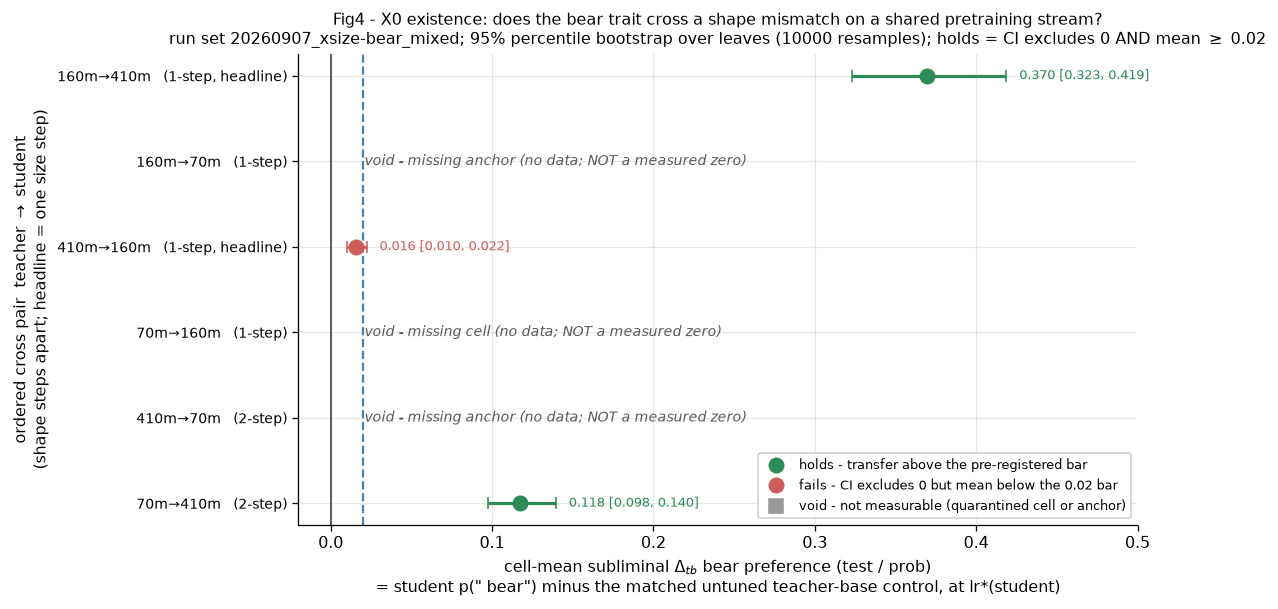

In [8]:
x0 = CLAIMS["X0"]
rows = []
for label, rec in x0["pairs"].items():
    teacher, student = label.split("→")
    rows.append({
        "pair": label, "teacher": teacher, "student": student,
        "status": rec["status"], "reason": rec.get("reason"),
        "mean": rec.get("mean", np.nan),
        "ci_low": (rec.get("ci") or [np.nan, np.nan])[0],
        "ci_high": (rec.get("ci") or [np.nan, np.nan])[1],
        "headline": bool(rec.get("headline", False)),
    })
x0_df = pd.DataFrame(rows)
x0_df["shape_steps"] = [abs(SIZES.index(s) - SIZES.index(t))
                        for t, s in zip(x0_df["teacher"], x0_df["student"])]
x0_df = x0_df.sort_values(["shape_steps", "teacher", "student"]).reset_index(drop=True)
display(x0_df)
print("X0 roll-up status:", x0["status"], "| min delta bar:", x0["min_delta"],
      "| endpoint:", x0["prompt_set"])
print("scored:", int((x0_df["status"] != "void").sum()),
      "| void:", int((x0_df["status"] == "void").sum()), "of", len(x0_df), "cross pairs")

fig, ax = plt.subplots(figsize=(10.2, 5.4))
y = np.arange(len(x0_df))
colours = {"holds": "seagreen", "fails": "indianred", "void": "0.6"}
for i, r in x0_df.iterrows():
    if r["status"] == "void":
        ax.text(0.021, i, f"void - {r['reason'].replace('_', ' ')} "
                          "(no data; NOT a measured zero)",
                va="center", fontsize=8.5, color="0.35", style="italic")
        continue
    ax.errorbar(
        r["mean"], i, xerr=[[r["mean"] - r["ci_low"]], [r["ci_high"] - r["mean"]]],
        fmt="o", ms=9, capsize=4, lw=2.0,
        color=colours[r["status"]], zorder=3,
    )
    ax.annotate(f"{r['mean']:.3f} {fmt_ci(r['ci_low'], r['ci_high'])}",
                (r["ci_high"], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=8, color=colours[r["status"]])
ax.axvline(0.0, color="0.3", lw=1.1)
ax.axvline(plan.X0_MIN_DELTA, color="steelblue", ls="--", lw=1.4)
ax.annotate(f"pre-registered existence bar\n$\\Delta_{{tb}} \\geq$ {plan.X0_MIN_DELTA}",
            (plan.X0_MIN_DELTA, len(x0_df) - 0.35), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color="steelblue")
labels = [
    f"{r['pair']}   ({r['shape_steps']}-step" + (", headline)" if r["headline"] else ")")
    for _, r in x0_df.iterrows()
]
ax.set_yticks(y, labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-0.02, 0.50)
ax.set_xlabel(
    "cell-mean subliminal $\\Delta_{tb}$ bear preference (test / prob)\n"
    "= student p(\" bear\") minus the matched untuned teacher-base control, at lr*(student)"
)
ax.set_ylabel("ordered cross pair  teacher $\\rightarrow$ student\n(shape steps apart; "
              "headline = one size step)")
ax.set_title(
    "Fig4 - X0 existence: does the bear trait cross a shape mismatch on a shared pretraining stream?\n"
    f"run set {plan.RUN_SET_ID}; 95% percentile bootstrap over leaves "
    f"({plan.BOOTSTRAP_N} resamples); holds = CI excludes 0 AND mean $\\geq$ {plan.X0_MIN_DELTA}",
    fontsize=10,
)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="none", color="seagreen", ms=9,
           label="holds - transfer above the pre-registered bar"),
    Line2D([], [], marker="o", ls="none", color="indianred", ms=9,
           label="fails - CI excludes 0 but mean below the 0.02 bar"),
    Line2D([], [], marker="s", ls="none", color="0.6", ms=9,
           label="void - not measurable (quarantined cell or anchor)"),
], loc="lower right", fontsize=8, framealpha=0.95)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Reading this figure

**Question answered:** For each ordered cross-size pair, does subliminal transfer
clear the pre-registered existence bar (CI excludes 0 and mean ≥ 0.02)?

**Conclusion from the plot:** X0 is **partial** — cross-size subliminal learning
demonstrably exists when the student is the larger model (160M→410M 0.370 and
70M→410M 0.118, both CIs far above the bar), demonstrably **fails** in the one
readable downward pair (410M→160M 0.016, CI [0.010, 0.022] excludes zero yet sits
below the 0.02 bar — a real but negligible effect), and the remaining three pairs
are void for lack of surviving 70M-student data.

**Axes.** y = ordered cross pair, annotated with shape distance in size steps and
whether it is a headline (one-step) pair. x = cell-mean `Δ_tb` with its 95%
bootstrap CI. Solid line = 0; dashed line = the 0.02 pre-registered bar.

**How the metric is calculated.** Read directly from `claims.json` `X0.pairs`,
which the pipeline scores as `holds` iff `not (ci_low <= 0 <= ci_high)` and
`mean >= X0_MIN_DELTA`. Void precedence is: no admissible teacher → missing anchor
→ anchor CI covers 0 → missing cell.

**What this does and does not license.** "Fails" here means *measured and below the
bar*; "void" means *not measured*. The two must not be pooled into "cross-size SL
does not work" — the only downward pair with data is 410M→160M.

## 6. Fig5 — X1 shape penalty against the student's own anchor

**What this measures.** X1 asks whether shape mismatch costs transfer *beyond* what
a different initialisation alone costs. The penalty is the absolute Δ shortfall of
a cross cell against the **same student's** same-shape anchor at the same learning
rate. `rho_s` restates it as a retained fraction; `efficiency` divides by the
teacher's own trait strength so a weak teacher is not misread as a shape penalty.

SCOPE: n=3 | teacher=3 | student=2 | lr=1 | shape_steps=2 | cross pairs with both a cross cell and a student anchor


,pair,shape_steps,lr,delta_tb,delta_anchor_s,delta_anchor_t,rho_s,rho_t,penalty,penalty_ci_low,penalty_ci_high,efficiency,teacher_p_target
0,160m→410m,1,0.0004,0.369560,0.372939,0.355994,0.990939,1.038108,0.003379,-0.060389,0.062972,1.337729,0.276259
1,70m→410m,2,0.0004,0.117600,0.372939,NaN,0.315333,NaN,0.255339,0.210427,0.300246,1.384860,0.084919
2,410m→160m,1,0.0004,0.015601,0.355994,0.372939,0.043824,0.041833,0.340392,0.297107,0.386223,0.033737,0.462436


X1 roll-up: partial | 2 of 3 pairs show a significant positive penalty


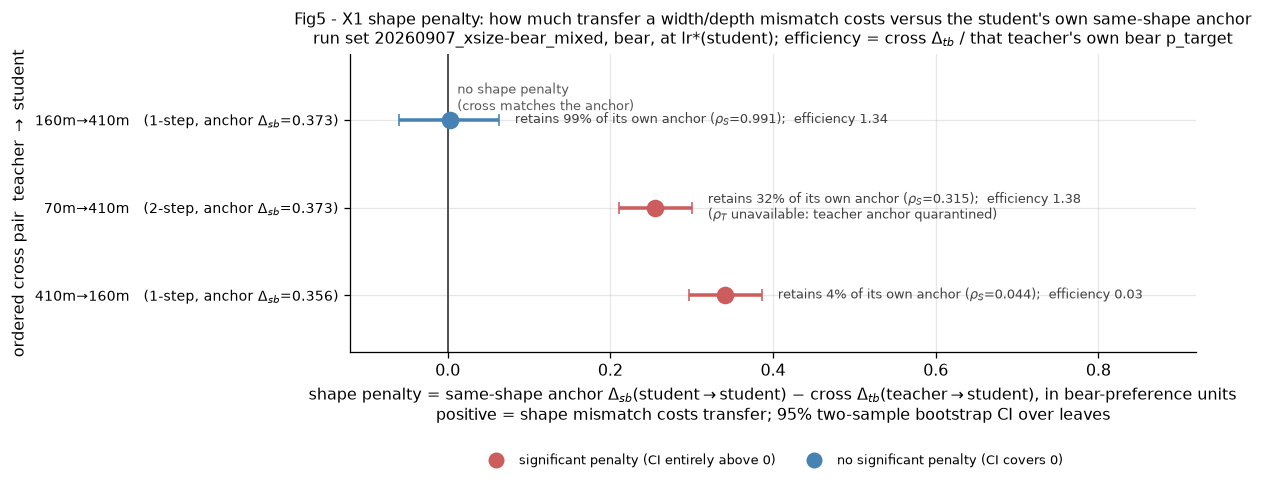


efficiency check - is a small penalty just a strong teacher, or vice versa?
  160m→410m    teacher dose 0.276 -> cross delta 0.370 = efficiency 1.338
  70m→410m     teacher dose 0.085 -> cross delta 0.118 = efficiency 1.385
  410m→160m    teacher dose 0.462 -> cross delta 0.016 = efficiency 0.034


In [9]:
pen = PENALTY.copy()
pen["pair"] = [pair_label(t, s) for t, s in zip(pen["teacher"], pen["student"])]
pen["shape_steps"] = [abs(SIZES.index(s) - SIZES.index(t))
                      for t, s in zip(pen["teacher"], pen["student"])]
pen = pen.sort_values("penalty").reset_index(drop=True)
scope(pen, "cross pairs with both a cross cell and a student anchor")
display(pen[["pair", "shape_steps", "lr", "delta_tb", "delta_anchor_s", "delta_anchor_t",
             "rho_s", "rho_t", "penalty", "penalty_ci_low", "penalty_ci_high",
             "efficiency", "teacher_p_target"]])
x1 = CLAIMS["X1"]
print("X1 roll-up:", x1["status"], f"| {x1['n_sig']} of {x1['n']} pairs show a "
      "significant positive penalty")

fig, ax = plt.subplots(figsize=(10.6, 4.6))
y = np.arange(len(pen))
for i, r in pen.iterrows():
    sig = bool(np.isfinite(r["penalty_ci_low"]) and r["penalty_ci_low"] > 0)
    ax.errorbar(
        r["penalty"], i,
        xerr=[[r["penalty"] - r["penalty_ci_low"]], [r["penalty_ci_high"] - r["penalty"]]],
        fmt="o", ms=10, capsize=4, lw=2.2,
        color="indianred" if sig else "steelblue", zorder=3,
    )
    ax.annotate(
        f"retains {100 * r['rho_s']:.0f}% of its own anchor "
        f"($\\rho_S$={r['rho_s']:.3f});  efficiency {r['efficiency']:.2f}"
        + ("" if np.isfinite(r["rho_t"]) else "\n($\\rho_T$ unavailable: teacher anchor quarantined)"),
        (max(r["penalty_ci_high"], r["penalty"]), i), xytext=(10, 0),
        textcoords="offset points", va="center", fontsize=8, color="0.25",
    )
ax.axvline(0.0, color="0.3", lw=1.2)
ax.annotate("no shape penalty\n(cross matches the anchor)", (0.0, -0.44),
            xytext=(6, 0), textcoords="offset points", va="top",
            fontsize=8, color="0.35")
ax.set_yticks(y, [f"{r['pair']}   ({int(r['shape_steps'])}-step, "
                  f"anchor $\\Delta_{{sb}}$={r['delta_anchor_s']:.3f})"
                  for _, r in pen.iterrows()], fontsize=9)
ax.set_ylim(len(pen) - 0.35, -0.75)
ax.set_xlim(-0.12, 0.92)
ax.set_xlabel(
    "shape penalty = same-shape anchor $\\Delta_{sb}$(student$\\rightarrow$student) "
    "$-$ cross $\\Delta_{tb}$(teacher$\\rightarrow$student), in bear-preference units\n"
    "positive = shape mismatch costs transfer; 95% two-sample bootstrap CI over leaves"
)
ax.set_ylabel("ordered cross pair  teacher $\\rightarrow$ student")
ax.set_title(
    "Fig5 - X1 shape penalty: how much transfer a width/depth mismatch costs "
    "versus the student's own same-shape anchor\n"
    f"run set {plan.RUN_SET_ID}, bear, at lr*(student); "
    "efficiency = cross $\\Delta_{tb}$ / that teacher's own bear p_target",
    fontsize=10,
)
ax.legend(handles=[
    Line2D([], [], marker="o", ls="none", color="indianred", ms=9,
           label="significant penalty (CI entirely above 0)"),
    Line2D([], [], marker="o", ls="none", color="steelblue", ms=9,
           label="no significant penalty (CI covers 0)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.30), ncol=2, fontsize=8, frameon=False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nefficiency check - is a small penalty just a strong teacher, or vice versa?")
for _, r in pen.iterrows():
    print(f"  {r['pair']:12s} teacher dose {r['teacher_p_target']:.3f} -> "
          f"cross delta {r['delta_tb']:.3f} = efficiency {r['efficiency']:.3f}")

### Reading this figure

**Question answered:** Beyond having a different initialisation, does a width/depth
mismatch itself cost subliminal transfer relative to the student's own same-shape
anchor?

**Conclusion from the plot:** The penalty is not a property of mismatch per se but
of its direction — 160M→410M shows **no** significant penalty (0.003, CI
[−0.060, 0.063] covering zero, ρ_S = 0.99, i.e. one size step upward is
effectively free), while 410M→160M loses almost everything (penalty 0.340, CI
[0.297, 0.386], ρ_S = 0.044) and two-step 70M→410M loses a significant but modest
0.255; crucially the efficiency column rules out the "weak teacher" explanation,
since 70M→410M converts its teacher's trait at 1.38 while 410M→160M converts at
only 0.034.

**Axes.** y = ordered cross pair, annotated with shape distance and the anchor it
is measured against. x = the penalty in bear-preference units with a 95%
two-sample bootstrap CI over leaves; 0 = the cross cell matches its anchor.
Annotations give ρ_S (fraction of the anchor retained) and efficiency.

**How the metric is calculated.** `xsize_penalty.csv`. **Note the column is a
difference, `delta_anchor_s − delta_tb`, not the `1 − ratio` the plan text
described** — both are reported here (`penalty` and `rho_s`) so neither is
ambiguous. `delta_anchor_t`/`rho_t` are NaN for 70M→410M because the 70M anchor
was quarantined out entirely (§3). `teacher_p_target` is the mean dose over
*admitted* teachers of that size at the gate's tag, not a single leaf.

**What this does and does not license.** With only three readable pairs and one of
them two-step, the "two-step ≤ one-step" ordering pre-registered in X1 cannot be
tested: the two-step pair (70M→410M) has a *smaller* penalty than the one-step
410M→160M, but they differ in direction as well as distance, so distance and
direction are confounded here.

## 7. Fig6 — X2 direction asymmetry: small→large versus large→small

**What this measures.** ι is the signed gap between the two directions of one
unordered size pair: `Δ_tb(small→large) − Δ_tb(large→small)`. X2 pre-registers
that ι CI excluding 0 with |ι| ≥ 0.05 reads as a **directional interaction** —
emissivity and receptivity are not separable. Only the 160M↔410M pair has both
directions surviving.

SCOPE: n=1 | unordered size pairs with both directions surviving


,size_lo,size_hi,iota,iota_dose,ci_low,ci_high,delta_up,delta_down
0,160m,410m,0.353959,1.303992,0.307193,0.403512,0.36956,0.015601


unordered pairs with no asymmetry row (one direction quarantined): 70m↔160m, 70m↔410m


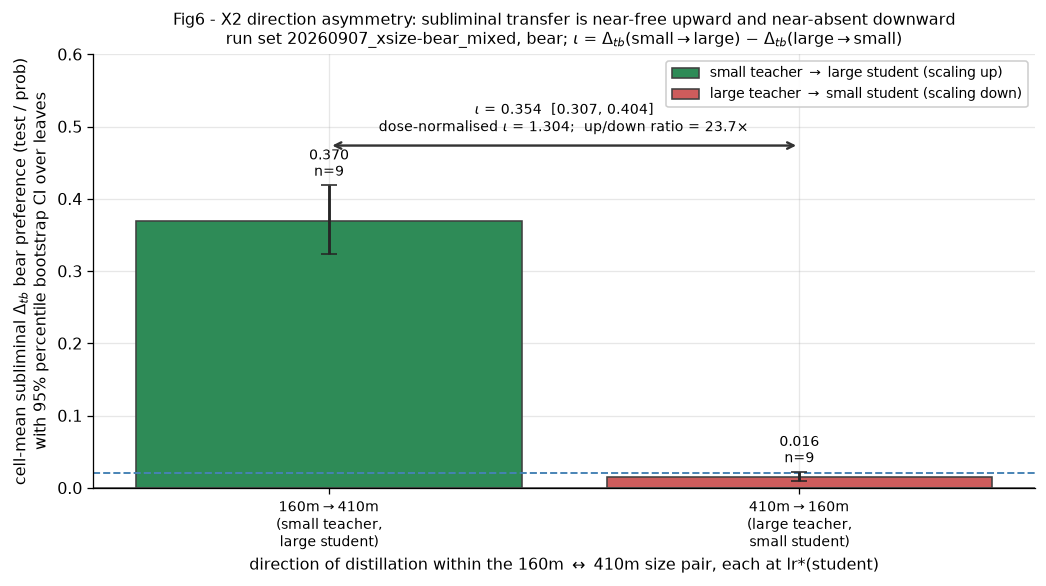

160m<->410m: iota=0.3540 [0.3072, 0.4035] | |iota| >= 0.05? True | CI excludes 0? True -> directional: True


In [10]:
asym = ASYM.copy()
scope(asym, "unordered size pairs with both directions surviving")
display(asym)
missing = [f"{a}↔{b}" for i, a in enumerate(SIZES) for b in SIZES[i + 1:]
           if not ((asym["size_lo"] == a) & (asym["size_hi"] == b)).any()]
print("unordered pairs with no asymmetry row (one direction quarantined):",
      ", ".join(missing) or "none")

star_idx = {(r["teacher"], r["student"]): r for _, r in star.iterrows()}
fig, ax = plt.subplots(figsize=(9.2, 5.2))
xpos, labels, colours = [], [], []
bars = []
for k, (_, r) in enumerate(asym.iterrows()):
    lo, hi = r["size_lo"], r["size_hi"]
    for off, (t, s, name, colour) in enumerate([
        (lo, hi, f"{lo}$\\rightarrow${hi}\n(small teacher,\nlarge student)", "seagreen"),
        (hi, lo, f"{hi}$\\rightarrow${lo}\n(large teacher,\nsmall student)", "indianred"),
    ]):
        cell = star_idx[(t, s)]
        pos = k * 2.6 + off
        bars.append(ax.bar(pos, cell["mean_delta_primary"], width=0.82, color=colour,
                           edgecolor="0.25", zorder=2))
        ax.errorbar(pos, cell["mean_delta_primary"],
                    yerr=[[cell["mean_delta_primary"] - cell["ci_low"]],
                          [cell["ci_high"] - cell["mean_delta_primary"]]],
                    fmt="none", ecolor="0.15", capsize=5, lw=1.8, zorder=3)
        ax.annotate(f"{cell['mean_delta_primary']:.3f}\nn={int(cell['n'])}",
                    (pos, cell["ci_high"]), xytext=(0, 6), textcoords="offset points",
                    ha="center", fontsize=8.5)
        xpos.append(pos)
        labels.append(name)
    mid = k * 2.6 + 0.5
    top = max(star_idx[(lo, hi)]["ci_high"], star_idx[(hi, lo)]["ci_high"])
    ax.annotate(
        "", xy=(k * 2.6, top + 0.055), xytext=(k * 2.6 + 1, top + 0.055),
        arrowprops={"arrowstyle": "<->", "color": "0.2", "lw": 1.5},
    )
    ax.text(mid, top + 0.068,
            f"$\\iota$ = {r['iota']:.3f}  {fmt_ci(r['ci_low'], r['ci_high'])}\n"
            f"dose-normalised $\\iota$ = {r['iota_dose']:.3f};  "
            f"up/down ratio = {r['delta_up'] / r['delta_down']:.1f}$\\times$",
            ha="center", va="bottom", fontsize=9)
ax.set_xticks(xpos, labels, fontsize=9)
ax.axhline(0.0, color="0.3", lw=1.0)
ax.axhline(plan.X0_MIN_DELTA, color="steelblue", ls="--", lw=1.2)
ax.annotate(f"X0 existence bar {plan.X0_MIN_DELTA}", (max(xpos) + 0.55, plan.X0_MIN_DELTA),
            xytext=(0, 4), textcoords="offset points", ha="right", fontsize=8, color="steelblue")
ax.set_ylim(0, 0.60)
ax.set_ylabel(
    "cell-mean subliminal $\\Delta_{tb}$ bear preference (test / prob)\n"
    "with 95% percentile bootstrap CI over leaves"
)
ax.set_xlabel("direction of distillation within the 160m $\\leftrightarrow$ 410m size pair, "
              "each at lr*(student)")
ax.set_title(
    "Fig6 - X2 direction asymmetry: subliminal transfer is near-free upward and "
    "near-absent downward\n"
    f"run set {plan.RUN_SET_ID}, bear; $\\iota$ = $\\Delta_{{tb}}$(small$\\rightarrow$large) "
    "$-$ $\\Delta_{tb}$(large$\\rightarrow$small)",
    fontsize=10,
)
ax.legend(handles=[
    mpl.patches.Patch(facecolor="seagreen", edgecolor="0.25",
                      label="small teacher $\\rightarrow$ large student (scaling up)"),
    mpl.patches.Patch(facecolor="indianred", edgecolor="0.25",
                      label="large teacher $\\rightarrow$ small student (scaling down)"),
], loc="upper right", fontsize=8.5, framealpha=0.95)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for _, r in asym.iterrows():
    directional = (not (r["ci_low"] <= 0 <= r["ci_high"])) and abs(r["iota"]) >= plan.X2_ASYM_MIN
    print(f"{r['size_lo']}<->{r['size_hi']}: iota={r['iota']:.4f} "
          f"{fmt_ci(r['ci_low'], r['ci_high'], 4)} "
          f"| |iota| >= {plan.X2_ASYM_MIN}? {abs(r['iota']) >= plan.X2_ASYM_MIN} "
          f"| CI excludes 0? {not (r['ci_low'] <= 0 <= r['ci_high'])} "
          f"-> directional: {directional}")

### Reading this figure

**Question answered:** Within one size pair, does it matter which model is the
teacher and which is the student — is subliminal transfer symmetric?

**Conclusion from the plot:** Strongly asymmetric — 160M→410M reaches 0.370 while
the reverse 410M→160M reaches only 0.016, an ι of 0.354 with CI [0.307, 0.404]
that excludes zero by a wide margin and a 23.7× up/down ratio, so the trait flows
readily into a larger student but essentially does not flow into a smaller one.

**Axes.** Bars = cell-mean `Δ_tb` for the two directions of the 160M↔410M pair,
each at its own student's `lr*`, with 95% bootstrap CIs and surviving-leaf counts.
The double arrow spans the two bars and reports ι, its CI, the dose-normalised ι,
and the raw ratio. Dashed line = the X0 existence bar.

**How the metric is calculated.** `xsize_asymmetry.csv`, where `size_lo` is the
**smaller** model and `iota = delta_up − delta_down`. The CI is an independent
two-sample bootstrap over the two arms' leaves. `iota_dose` divides each direction
by its own teacher's dose first, which matters because the 160M and 410M teachers
differ in trait strength (0.276 vs 0.462).

**What this does and does not license.** This is one size pair. The 70M↔160M and
70M↔410M asymmetries are unmeasurable here, so "small→large is easier" is
established for the 160M↔410M step only, and cannot yet be stated as a general
scaling law.

## 8. X2 additive fit — table only, because the fit is degenerate

**What this measures.** X2's second half asks whether the 3×3 matrix separates into
a teacher-side emissivity τ and a student-side receptivity σ (`Δ_ij = τ_i + σ_j`).
That model has 5 free parameters after the `mean(σ) = 0` identification. With only
**5 surviving cells** it is saturated, so R² and the leave-one-pair-out diagnostics
are not informative. **No figure is drawn**, deliberately: plotting a saturated fit
would imply evidence that does not exist.

In [11]:
add = ADDITIVE.copy()
scalars = {r["field"]: r["value"] for _, r in add.loc[add["key"].isna()].iterrows()}
tau = add.loc[add["field"] == "tau"].set_index("key")["value"].reindex(SIZES)
sigma = add.loc[add["field"] == "sigma"].set_index("key")["value"].reindex(SIZES)
loo = add.loc[add["field"] == "loo_r2"].set_index("key")["value"]
resid = add.loc[add["field"] == "residuals"].set_index("key")["value"]

n_cells_fit = len(star)
n_params = 2 * len(SIZES) - 1
print(f"cells available to the fit: {n_cells_fit} | free parameters: {n_params} "
      f"(3 tau + 3 sigma - 1 centering constraint)")
print(f"residual degrees of freedom: {n_cells_fit - n_params}  "
      "-> the fit is saturated / under-identified; treat tau and sigma as descriptive only")

est = pd.DataFrame({
    "tau (teacher-side emissivity)": tau,
    "sigma (student-side receptivity, mean 0)": sigma,
})
est.index.name = "size"
display(est.round(4))
print("full-fit R2:", round(float(scalars["r2"]), 4),
      "| X2 bar:", plan.X2_ADDITIVE_R2_MIN,
      "-> passes:", float(scalars["r2"]) >= plan.X2_ADDITIVE_R2_MIN)
print("pooled iota:", round(float(scalars["pooled_iota"]), 4),
      "| CI:", (scalars["pooled_iota_ci_low"], scalars["pooled_iota_ci_high"]),
      "(NaN because at least one unordered pair has no surviving leaves on one side)")
print("\nleave-one-reciprocal-pair-out R2:")
display(loo.rename("loo_r2").to_frame().round(4))
print("\nresiduals (observed cell minus tau_i + sigma_j):")
display(resid.rename("residual").to_frame().round(6))

x2 = CLAIMS["X2"]
print(f"\nX2 status: {x2['status']} | read: {x2['read']}")
print("NOTE: the pipeline adjudicates X2 on the FULL-fit R2 "
      f"({float(scalars['r2']):.4f}), whereas prereg section 6 describes the "
      "leave-one-reciprocal-pair-out R2. Both are shown above; neither rescues the "
      "claim, because the pooled iota CI is undefined and the fit is saturated.")
print("The +/-0.0859 residual pattern on the four 160m/410m cells and the exact "
      "1.0 leave-one-out R2 for 160m<->410m are signatures of that saturation, "
      "not of a well-supported additive structure.")

cells available to the fit: 5 | free parameters: 5 (3 tau + 3 sigma - 1 centering constraint)
residual degrees of freedom: 0  -> the fit is saturated / under-identified; treat tau and sigma as descriptive only


,tau (teacher-side emissivity),"sigma (student-side receptivity, mean 0)"
size,,
70m,-0.0595,-0.1687
160m,0.2784,-0.0084
410m,0.1099,0.1771


full-fit R2: 0.7387 | X2 bar: 0.85 -> passes: False
pooled iota: 0.354 | CI: (nan, nan) (NaN because at least one unordered pair has no surviving leaves on one side)

leave-one-reciprocal-pair-out R2:


,loo_r2
key,
70m↔160m,0.7387
70m↔410m,0.6800
160m↔410m,1.0000



residuals (observed cell minus tau_i + sigma_j):


,residual
key,
70m→410m,0.000000
160m→160m,0.085943
160m→410m,-0.085943
410m→160m,-0.085943
410m→410m,0.085943



X2 status: fails | read: None
NOTE: the pipeline adjudicates X2 on the FULL-fit R2 (0.7387), whereas prereg section 6 describes the leave-one-reciprocal-pair-out R2. Both are shown above; neither rescues the claim, because the pooled iota CI is undefined and the fit is saturated.
The +/-0.0859 residual pattern on the four 160m/410m cells and the exact 1.0 leave-one-out R2 for 160m<->410m are signatures of that saturation, not of a well-supported additive structure.


### Reading this table

**Question answered:** Does the cross-size transfer matrix decompose into a
per-teacher "emissivity" and a per-student "receptivity"?

**Conclusion from the output:** Unanswerable in this run — the additive model needs
5 parameters and only 5 cells survived, leaving zero residual degrees of freedom,
so the reported full-fit R² of 0.739 (below the 0.85 bar) and the undefined pooled
ι CI mean **X2 fails for lack of data, not because separability was tested and
rejected**; the exact ±0.0859 residual symmetry and the 1.000 leave-one-out R² on
160M↔410M are arithmetic artefacts of saturation.

**Why no figure.** A τ/σ bar chart would render five numbers estimated from five
observations as if they carried uncertainty information. The honest presentation is
the table plus the degrees-of-freedom line.

## 9. Fig7 — X3 learning-rate robustness

**What this measures.** X3 is descriptive: are the X0/X2 reads an artefact of the
student learning rate? Two views of the same question — the anchor Δ vs LR ladder
per student size (P2), and the one-step cross pairs at every LR they were run at
(P3b). Note up front that `lr*` was **flagged** for 70M and 160M: no rung passed
the ≤1.5 perplexity guard, so 4e-4 is a default fallback there, not an earned pick.

anchor ladder cells that survived quarantine (P2):


,student,lr,n,mean_delta_sb,ci_low,ci_high,mean_ppl_ratio
0,160m,0.0002,3,0.195613,0.099218,0.265452,2.531616
1,160m,0.0004,9,0.355994,0.312398,0.401726,2.441651
6,410m,0.0002,3,0.404205,0.371265,0.435475,1.456444
7,410m,0.0004,9,0.372939,0.333186,0.413145,1.471710
8,410m,0.0008,3,0.396550,0.352068,0.444087,1.476663


anchor ladder rungs with no surviving leaves: 70m@2e-04, 70m@4e-04, 70m@8e-04, 160m@8e-04

X3 cross-pair LR table (xsize_lr.csv; kendall_tau is one value per LR, repeated across that LR's rows):


,lr,teacher,student,delta_tb,sign,kendall_tau,picked_lr
0,0.0002,70m,160m,0.009942,1,NaN,0.0004
1,0.0002,410m,160m,0.008338,1,NaN,0.0004
2,0.0004,160m,410m,0.369560,1,1.0,0.0004
3,0.0004,410m,160m,0.015601,1,1.0,0.0004
4,0.0008,410m,160m,0.007709,1,NaN,0.0004


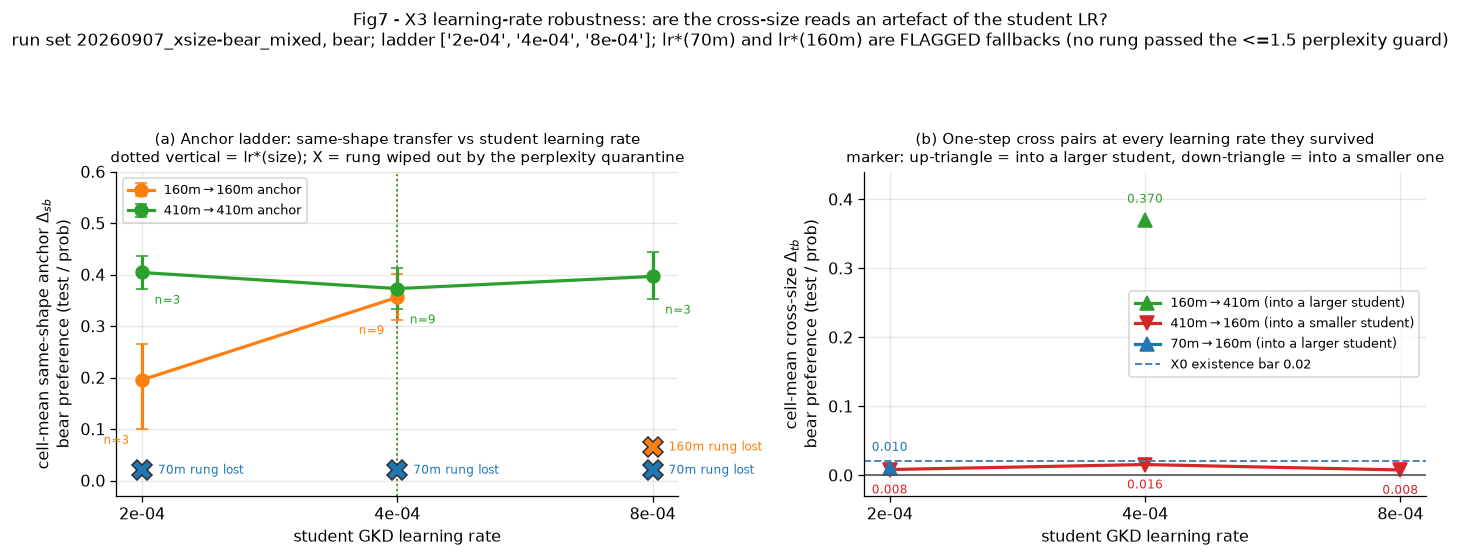

X3 status: descriptive | signs stable across the ladder: True | mean Kendall tau vs the ranking at lr*: 1.0
pairs whose sign differs between lr* and the 4e-4 default: none (lr* == 4e-4 everywhere, so this list is never populated by construction)

per-LR Kendall tau (one value per LR, not a row mean):


,kendall_tau
lr,
0.0002,NaN
0.0004,1.0
0.0008,NaN


In [12]:
lad = CELLS.loc[CELLS["arm"] == "anchor"].sort_values(["student", "lr"])
print("anchor ladder cells that survived quarantine (P2):")
display(lad[["student", "lr", "n", "mean_delta_sb", "ci_low", "ci_high", "mean_ppl_ratio"]])
missing_lad = [(s, lr) for s in SIZES for lr in plan.LR_LADDER
               if not ((lad["student"] == s) & (np.isclose(lad["lr"], lr))).any()]
print("anchor ladder rungs with no surviving leaves:",
      ", ".join(f"{s}@{lr:.0e}" for s, lr in missing_lad) or "none")
print("\nX3 cross-pair LR table (xsize_lr.csv; kendall_tau is one value per LR, "
      "repeated across that LR's rows):")
display(LR)

fig, axs = plt.subplots(1, 2, figsize=(12.4, 4.9))

ax = axs[0]
for size in SIZES:
    sub = lad.loc[lad["student"] == size].sort_values("lr")
    if sub.empty:
        continue
    ax.errorbar(
        sub["lr"], sub["mean_delta_sb"],
        yerr=[sub["mean_delta_sb"] - sub["ci_low"], sub["ci_high"] - sub["mean_delta_sb"]],
        fmt="o-", ms=8, capsize=4, lw=2.0, color=palette[size],
        label=f"{size}$\\rightarrow${size} anchor",
    )
    dx = -16 if size == "160m" else 16
    for _, r in sub.iterrows():
        ax.annotate(f"n={int(r['n'])}", (r["lr"], r["ci_low"]),
                    xytext=(dx, -9), textcoords="offset points", ha="center",
                    fontsize=7.5, color=palette[size])
miss_by_lr: dict[float, list[str]] = {}
for size, lr in missing_lad:
    miss_by_lr.setdefault(lr, []).append(size)
for lr, sizes_missing in miss_by_lr.items():
    for k, size in enumerate(sorted(sizes_missing, key=SIZES.index)):
        yy = 0.02 + 0.045 * k
        ax.plot(lr, yy, marker="X", ms=12, color=palette[size], mec="0.2", mew=1.0,
                ls="none", zorder=4)
        ax.annotate(f"{size} rung lost", (lr, yy), xytext=(10, 0),
                    textcoords="offset points", va="center", fontsize=7.5,
                    color=palette[size])
for size in SIZES:
    ax.axvline(LR_STAR[size], color=palette[size], ls=":", lw=1.2, alpha=0.8)
ax.set_ylim(-0.03, 0.60)
ax.set_xscale("log")
ax.set_xticks(list(plan.LR_LADDER), [f"{v:.0e}" for v in plan.LR_LADDER])
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel("student GKD learning rate")
ax.set_ylabel("cell-mean same-shape anchor $\\Delta_{sb}$\nbear preference (test / prob)")
ax.set_title("(a) Anchor ladder: same-shape transfer vs student learning rate\n"
             "dotted vertical = lr*(size); X = rung wiped out by the perplexity quarantine",
             fontsize=9.5)
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

ax = axs[1]
PAIR_COLOUR = {("160m", "410m"): "tab:green", ("410m", "160m"): "tab:red",
               ("70m", "160m"): "tab:blue", ("160m", "70m"): "tab:purple"}
for (t, s), sub in LR.groupby(["teacher", "student"]):
    sub = sub.sort_values("lr")
    up = SIZES.index(s) > SIZES.index(t)
    ax.plot(sub["lr"], sub["delta_tb"], "-", ms=9, lw=2.0,
            color=PAIR_COLOUR[(t, s)], marker="^" if up else "v",
            label=f"{t}$\\rightarrow${s} " + ("(into a larger student)" if up
                                              else "(into a smaller student)"))
    for _, r in sub.iterrows():
        ax.annotate(f"{r['delta_tb']:.3f}", (r["lr"], r["delta_tb"]),
                    xytext=(0, 11 if up else -15), textcoords="offset points",
                    ha="center", fontsize=7.5, color=PAIR_COLOUR[(t, s)])
ax.axhline(0.0, color="0.3", lw=1.0)
ax.axhline(plan.X0_MIN_DELTA, color="steelblue", ls="--", lw=1.2,
           label=f"X0 existence bar {plan.X0_MIN_DELTA}")
ax.set_ylim(-0.03, 0.44)
ax.set_xscale("log")
ax.set_xticks(list(plan.LR_LADDER), [f"{v:.0e}" for v in plan.LR_LADDER])
ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax.set_xlabel("student GKD learning rate")
ax.set_ylabel("cell-mean cross-size $\\Delta_{tb}$\nbear preference (test / prob)")
ax.set_title("(b) One-step cross pairs at every learning rate they survived\n"
             "marker: up-triangle = into a larger student, down-triangle = into a smaller one",
             fontsize=9.5)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

fig.suptitle(
    "Fig7 - X3 learning-rate robustness: are the cross-size reads an artefact of the student LR?\n"
    f"run set {plan.RUN_SET_ID}, bear; ladder {[f'{v:.0e}' for v in plan.LR_LADDER]}; "
    "lr*(70m) and lr*(160m) are FLAGGED fallbacks (no rung passed the <=1.5 perplexity guard)",
    fontsize=10.5,
)
plt.tight_layout(rect=(0, 0, 1, 0.90))
plt.show()

x3 = CLAIMS["X3"]
print("X3 status:", x3["status"], "| signs stable across the ladder:", x3["signs_stable"],
      "| mean Kendall tau vs the ranking at lr*:", x3["kendall_tau_mean"])
print("pairs whose sign differs between lr* and the 4e-4 default:",
      x3["lr_star_vs_default"] or "none (lr* == 4e-4 everywhere, so this list is "
      "never populated by construction)")
print("\nper-LR Kendall tau (one value per LR, not a row mean):")
display(LR.groupby("lr")["kendall_tau"].first().rename("kendall_tau").to_frame())

### Reading this figure

**Question answered:** Do the cross-size conclusions survive changing the student
learning rate, or are they an optimisation artefact?

**Conclusion from the plot:** As far as the surviving data can say, the reads are
LR-stable — every measured Δ keeps a positive sign at every rung (`signs_stable`
true, Kendall τ = 1.0 where computable), the 410M anchor is essentially flat across
the whole ladder (0.404 / 0.373 / 0.397), and 410M→160M stays near-zero at all
three rates (0.008 / 0.016 / 0.008) — but this is weak evidence, because the 70M
ladder is entirely missing and the 160M ladder lost its 8e-4 rung, so no pair is
observed at more than three points and two of the three `lr*` picks were forced
fallbacks rather than earned optima.

**Axes.** (a) x = student LR (log, the three ladder rungs); y = cell-mean anchor
`Δ_sb` per student size with 95% CIs and leaf counts; a large **X** marker on the
zero line marks a rung whose leaves were all quarantined, labelled with the size
that lost it. Dotted verticals = `lr*`. (b) x = same LR axis; y = cell-mean cross
`Δ_tb`, one colour per ordered pair and marker shape encoding direction
(up-triangle into a larger student, down-triangle into a smaller one).

**How the metric is calculated.** Panel (a) from `xsize_cells.csv` `arm == "anchor"`;
panel (b) from `xsize_lr.csv`, whose `delta_tb` is already a cell mean. `kendall_tau`
is a single value per LR repeated across that LR's rows, so it is read with
`groupby("lr").first()`, never averaged over rows.

**What this does and does not license.** X3 is pre-registered as **descriptive**.
Stability here does not upgrade any X0 read; and because `lr*` equals the 4e-4
default everywhere, the `lr_star_vs_default` disagreement list is empty by
construction rather than by evidence.

## 10. Fig8 — X4 capability coupling and where the quarantine cut

**What this measures.** X4 asks whether Δ is really a trait transfer rather than a
by-product of capability damage. The scatter is every treatment leaf's Δ against
its own perplexity ratio, with the quarantine bound drawn, so the reader can see
both the coupling and precisely where the guard removed data. The pipeline's
formal X4 statistic is reported alongside — **and disputed**, for reasons the
second cell prints.

SCOPE: n=78 | animal=1 | teacher=3 | student=2 | kind=1 | phase=3 | arm=2 | lr=3 | ftseed=3 | gseed=3 | direction=3 | shape_steps=3 | treatment leaves with a delta (quarantined rows included)
leaves plotted: 78 | kept 63 | quarantined 15
student sizes present in the delta frame: ['160m', '410m'] - 70m students never reach this frame: their controls were quarantined too, so no delta could be formed


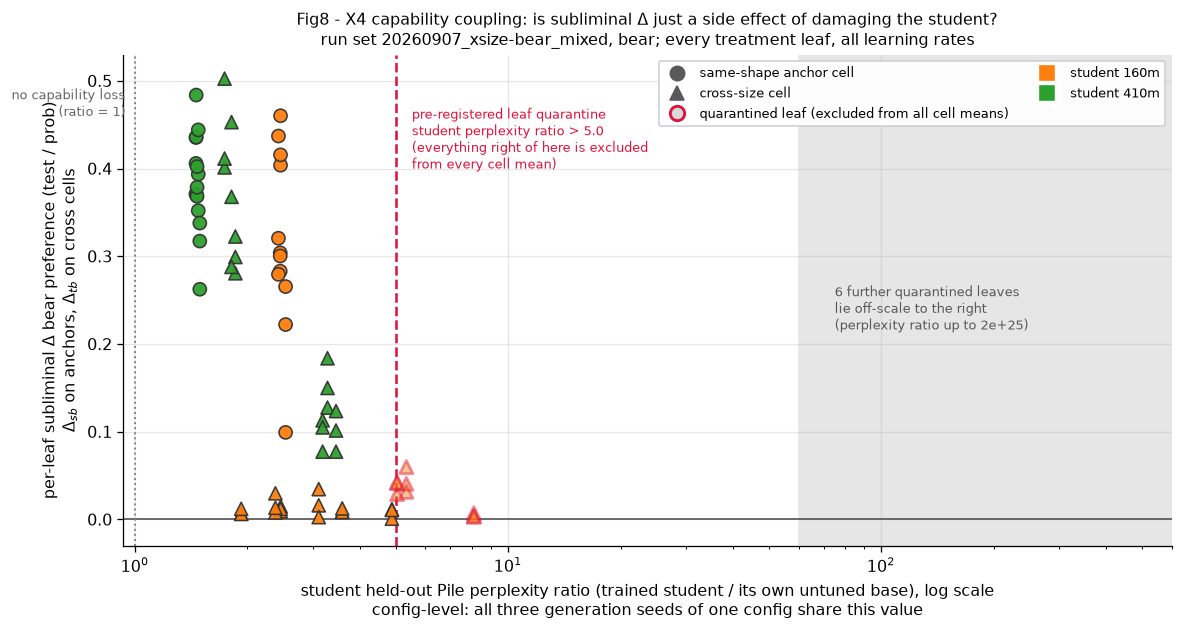


among SURVIVING leaves, Spearman correlation of delta with perplexity ratio:
  rho = -0.682 (n=63)


In [13]:
d = DELTA.copy()
d["kept"] = ~d["quarantined"].astype(bool)
scope(d, "treatment leaves with a delta (quarantined rows included)")
print(f"leaves plotted: {len(d)} | kept {int(d['kept'].sum())} | "
      f"quarantined {int((~d['kept']).sum())}")

fig, ax = plt.subplots(figsize=(10.4, 5.6))
for arm, marker in (("anchor", "o"), ("cross", "^")):
    for keep, alpha, edge in ((True, 0.95, "0.2"), (False, 0.45, "crimson")):
        sub = d.loc[(d["arm"] == arm) & (d["kept"] == keep)]
        if sub.empty:
            continue
        ax.scatter(
            sub["perplexity_ratio"], sub["delta_primary"], marker=marker, s=68,
            c=[palette[s] for s in sub["student"]], alpha=alpha,
            edgecolors=edge, linewidths=1.0 if keep else 1.8, zorder=3,
        )
X_MAX = 60.0
n_offscale = int((d["perplexity_ratio"] > X_MAX).sum())
ax.axvline(plan.QUARANTINE_PPL_RATIO_MAX, color="crimson", ls="--", lw=1.6)
ax.annotate(
    f"pre-registered leaf quarantine\nstudent perplexity ratio > {plan.QUARANTINE_PPL_RATIO_MAX}\n"
    "(everything right of here is excluded\nfrom every cell mean)",
    (plan.QUARANTINE_PPL_RATIO_MAX, 0.40), xytext=(10, 0), textcoords="offset points",
    fontsize=8, color="crimson",
)
ax.axhline(0.0, color="0.3", lw=1.0)
ax.axvline(1.0, color="0.5", ls=":", lw=1.2)
ax.annotate("no capability loss\n(ratio = 1)", (1.0, 0.46), xytext=(-6, 0),
            textcoords="offset points", ha="right", fontsize=8, color="0.4")
ax.axvspan(X_MAX, 1e3, color="0.9", zorder=0)
ax.annotate(
    f"{n_offscale} further quarantined leaves\nlie off-scale to the right\n"
    f"(perplexity ratio up to {d['perplexity_ratio'].max():.0e})",
    (X_MAX * 1.25, 0.24), fontsize=8, color="0.35", va="center",
)
ax.set_xscale("log")
ax.set_xlim(0.93, 6e2)
ax.set_ylim(-0.03, 0.53)
ax.set_xlabel(
    "student held-out Pile perplexity ratio (trained student / its own untuned base), log scale\n"
    "config-level: all three generation seeds of one config share this value"
)
ax.set_ylabel("per-leaf subliminal $\\Delta$ bear preference (test / prob)\n"
              "$\\Delta_{sb}$ on anchors, $\\Delta_{tb}$ on cross cells")
ax.set_title(
    "Fig8 - X4 capability coupling: is subliminal $\\Delta$ just a side effect of "
    "damaging the student?\n"
    f"run set {plan.RUN_SET_ID}, bear; every treatment leaf, all learning rates",
    fontsize=10,
)
handles = [
    Line2D([], [], marker="o", ls="none", color="0.35", ms=9, label="same-shape anchor cell"),
    Line2D([], [], marker="^", ls="none", color="0.35", ms=9, label="cross-size cell"),
    Line2D([], [], marker="o", ls="none", mfc="0.85", mec="crimson", mew=1.8, ms=9,
           label="quarantined leaf (excluded from all cell means)"),
] + [Line2D([], [], marker="s", ls="none", color=palette[s], ms=9, label=f"student {s}")
     for s in SIZES if (d["student"] == s).any()]
ax.legend(handles=handles, fontsize=8, loc="upper right", framealpha=0.95, ncol=2)
print("student sizes present in the delta frame:", sorted(d["student"].unique(), key=SIZES.index),
      "- 70m students never reach this frame: their controls were quarantined too, "
      "so no delta could be formed")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

kept_d = live(d)
print("\namong SURVIVING leaves, Spearman correlation of delta with perplexity ratio:")
print("  rho =", round(float(kept_d["delta_primary"].corr(
    kept_d["perplexity_ratio"], method="spearman")), 4), f"(n={len(kept_d)})")

In [14]:
x4 = CLAIMS["X4"]
print(f"pipeline X4: status={x4['status']} "
      f"retained_fraction={x4['retained_fraction']:.4f} >= {x4['threshold']}")
print("\nper-(teacher, student, lr) residualisation groups behind that mean:")
show = PPL.copy()
show["constant_regressor"] = show["beta"] == 0.0
show["delta_adj_in_range"] = show["mean_delta_adj"].between(0.0, 1.0)
display(show.round(4))

n_const = int(show["constant_regressor"].sum())
n_oob = int((~show["delta_adj_in_range"]).sum())
n_gt1 = int((show["retained_fraction"] > 1.0).sum())
print(f"\nDO NOT LEAN ON X4. Of {len(show)} groups:")
print(f"  - {n_const} have beta exactly 0.0: their group holds a single config, so the "
      "regressor is constant and\n    retained_fraction is forced to exactly 1.0 by "
      "construction, not by evidence.")
print(f"  - {n_oob} have a residualised mean delta outside the [0, 1] probability range "
      f"(min {show['mean_delta_adj'].min():.3f}, max {show['mean_delta_adj'].max():.3f}).")
print(f"  - {n_gt1} have retained_fraction > 1.0, i.e. residualising made the effect "
      "look LARGER.")
print(f"  - beta ranges {show['beta'].min():.3f} to {show['beta'].max():.3f} across groups, "
      "with no consistent sign.")
print("\nThe headline 1.859 is an unweighted mean over these groups and inherits every "
      "one of those defects.\nThe scatter above, and the fact that the two strongest "
      "cells (160m->410m, 410m->410m) carry the\nLOWEST perplexity ratios (1.80 and 1.47), "
      "are better evidence that delta is not capability damage\nthan the X4 statistic is.")

pipeline X4: status=holds retained_fraction=1.8586 >= 0.5

per-(teacher, student, lr) residualisation groups behind that mean:


,teacher,student,lr,beta,mean_delta,mean_delta_adj,retained_fraction,n,constant_regressor,delta_adj_in_range
0,160m,160m,0.0002,0.0000,0.1956,0.1956,1.0000,3,True,True
1,160m,160m,0.0004,1.0669,0.3560,-1.1821,3.3205,9,False,False
2,160m,410m,0.0004,-1.1208,0.3696,1.2688,3.4334,9,False,False
3,410m,160m,0.0002,0.0000,0.0083,0.0083,1.0000,3,True,True
4,410m,160m,0.0004,0.0040,0.0156,0.0090,0.5744,9,False,True
5,410m,160m,0.0008,0.0000,0.0077,0.0077,1.0000,3,True,True
6,410m,410m,0.0002,0.0000,0.4042,0.4042,1.0000,3,True,True
7,410m,410m,0.0004,-3.6006,0.3729,2.0714,5.5542,9,False,False
8,410m,410m,0.0008,0.0000,0.3965,0.3965,1.0000,3,True,True
9,70m,160m,0.0002,0.0000,0.0099,0.0099,1.0000,3,True,True



DO NOT LEAN ON X4. Of 11 groups:
  - 6 have beta exactly 0.0: their group holds a single config, so the regressor is constant and
    retained_fraction is forced to exactly 1.0 by construction, not by evidence.
  - 3 have a residualised mean delta outside the [0, 1] probability range (min -1.182, max 2.071).
  - 4 have retained_fraction > 1.0, i.e. residualising made the effect look LARGER.
  - beta ranges -3.601 to 1.067 across groups, with no consistent sign.

The headline 1.859 is an unweighted mean over these groups and inherits every one of those defects.
The scatter above, and the fact that the two strongest cells (160m->410m, 410m->410m) carry the
LOWEST perplexity ratios (1.80 and 1.47), are better evidence that delta is not capability damage
than the X4 statistic is.


### Reading this figure

**Question answered:** Is the measured subliminal Δ a genuine trait transfer, or a
by-product of GKD degrading the student's language modelling?

**Conclusion from the plot:** The scatter argues against a capability artefact —
the largest Δ values sit at the *lowest* perplexity ratios (160M→410M at 0.370 with
ratio 1.80 and the 410M anchor at 0.373 with ratio 1.47), while the leaves with
catastrophic perplexity cluster near Δ ≈ 0 and are exactly the ones the quarantine
removed; the relationship among surviving leaves is negative, not the positive
coupling a capability artefact would produce.

**Axes.** x = per-leaf student perplexity ratio (log; 1.0 = undamaged), y = per-leaf
Δ. Colour = student size, marker shape = anchor vs cross, red outline = quarantined.
Dashed red line = the 5.0 quarantine bound. The x-axis is **truncated at 60** so the
readable region is not compressed by catastrophic outliers; the shaded band on the
right carries a count of the leaves that lie beyond it (perplexity ratios reaching
~2×10²⁵). No 70M-student leaf appears at all — its controls were quarantined too, so
no Δ could be formed for it.

**How the metric is calculated.** Points are `xsize_delta.csv` leaves (quarantined
rows shown but excluded from every aggregate). The pipeline's X4 statistic is the
unweighted mean of `retained_fraction` over `(teacher, student, lr)` groups from
`xsize_ppl.csv`.

**What this does and does not license.** The formal X4 "holds" verdict should
**not** be quoted: as the printed diagnostics show, 6 of 11 groups have a constant
regressor that forces `retained_fraction` to exactly 1.0, several residualised
means fall outside the probability range, and β has no stable sign. The visual and
correlational evidence above supports the conclusion; the X4 number does not
support anything.

## 11. Fig9 — concordance with the same-shape bear checkpoint grid

**What this measures.** A sanity join against `20260828_ckptgrid-bear_160m` at
step143000, which measured same-shape transfer with the same teacher tag, student
recipe and prompt pool. It is **descriptive only** — different code pin, no data is
read from that campaign; the reference numbers are frozen constants in
`xsize_plan.GRID_REFERENCE`. It answers "did this campaign reproduce what we
already knew?", not any X-claim.

,value
anchor_delta,0.355994
di_ds_delta,0.192581
teacher_p_target,0.276259
ref_run_set_id,20260828_ckptgrid-bear_160m
ref_step,143000
ref_anchor_delta,0.336
ref_di_ds_delta,0.265
ref_teacher_p_target,0.263


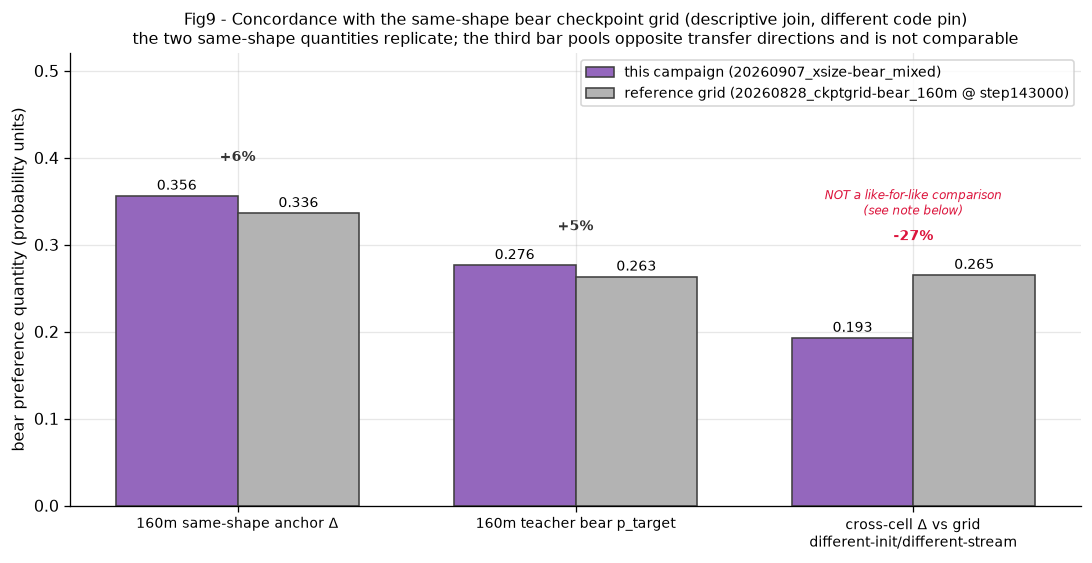


WHY THE THIRD BAR IS NOT COMPARABLE:
grid_concordance.di_ds_delta is an unweighted mean of the cell-mean cross deltas over whichever
one-step pairs survived - here just ['160m→410m', '410m→160m'] = (0.3696 + 0.0156) / 2 = 0.1926.
Those two cells differ by 23.7x and point in opposite directions (Fig6), so their mean is not an
effect size; it is the midpoint of a bimodal pair. The grid's 0.265 is a same-shape, different-init
mean over 30 cells. Comparing them would be a category error.

The two like-for-like quantities replicate well:
  anchor delta      0.3560 vs 0.336 (+6.0%)
  teacher p_target  0.2763 vs 0.263 (+5.0%)


In [15]:
c = CONCORD.iloc[0]
display(CONCORD.T.rename(columns={0: "value"}))

items = [
    ("160m same-shape anchor $\\Delta$", c["anchor_delta"], c["ref_anchor_delta"], True),
    ("160m teacher bear p_target", c["teacher_p_target"], c["ref_teacher_p_target"], True),
    ("cross-cell $\\Delta$ vs grid\ndifferent-init/different-stream",
     c["di_ds_delta"], c["ref_di_ds_delta"], False),
]
fig, ax = plt.subplots(figsize=(9.6, 5.0))
x = np.arange(len(items))
w = 0.36
ax.bar(x - w / 2, [v for _, v, _, _ in items], w, color="tab:purple",
       edgecolor="0.25", label=f"this campaign ({plan.RUN_SET_ID})", zorder=2)
ax.bar(x + w / 2, [r for _, _, r, _ in items], w, color="0.7",
       edgecolor="0.25", label=f"reference grid ({c['ref_run_set_id']} @ step{int(c['ref_step'])})",
       zorder=2)
for i, (_, v, r, comparable) in enumerate(items):
    ax.annotate(f"{v:.3f}", (i - w / 2, v), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.5)
    ax.annotate(f"{r:.3f}", (i + w / 2, r), xytext=(0, 4), textcoords="offset points",
                ha="center", fontsize=8.5)
    ax.annotate(f"{100 * (v - r) / r:+.0f}%", (i, max(v, r)), xytext=(0, 22),
                textcoords="offset points", ha="center", fontsize=9,
                color="0.2" if comparable else "crimson", fontweight="bold")
    if not comparable:
        ax.annotate("NOT a like-for-like comparison\n(see note below)", (i, max(v, r)),
                    xytext=(0, 38), textcoords="offset points", ha="center",
                    fontsize=7.5, color="crimson", style="italic")
ax.set_xticks(x, [label for label, _, _, _ in items], fontsize=9)
ax.set_ylabel("bear preference quantity (probability units)")
ax.set_ylim(0, 0.52)
ax.set_title(
    "Fig9 - Concordance with the same-shape bear checkpoint grid (descriptive join, different code pin)\n"
    "the two same-shape quantities replicate; the third bar pools opposite transfer directions "
    "and is not comparable",
    fontsize=10,
)
ax.legend(fontsize=8.5, loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

one_step_star = star.loc[star["arm"] == "cross"]
pooled = [pair_label(r["teacher"], r["student"]) for _, r in one_step_star.iterrows()
          if (r["teacher"], r["student"]) in [tuple(p) for p in plan.ONE_STEP_PAIRS]]
print("\nWHY THE THIRD BAR IS NOT COMPARABLE:")
print("grid_concordance.di_ds_delta is an unweighted mean of the cell-mean cross deltas over "
      "whichever\none-step pairs survived - here just", pooled, "=",
      f"({0.36955986034102456:.4f} + {0.015601173910235957:.4f}) / 2 = {c['di_ds_delta']:.4f}.")
print("Those two cells differ by 23.7x and point in opposite directions (Fig6), so their mean "
      "is not an\neffect size; it is the midpoint of a bimodal pair. The grid's 0.265 is a "
      "same-shape, different-init\nmean over 30 cells. Comparing them would be a category error.")
print("\nThe two like-for-like quantities replicate well:")
print(f"  anchor delta      {c['anchor_delta']:.4f} vs {c['ref_anchor_delta']:.3f} "
      f"({100 * (c['anchor_delta'] - c['ref_anchor_delta']) / c['ref_anchor_delta']:+.1f}%)")
print(f"  teacher p_target  {c['teacher_p_target']:.4f} vs {c['ref_teacher_p_target']:.3f} "
      f"({100 * (c['teacher_p_target'] - c['ref_teacher_p_target']) / c['ref_teacher_p_target']:+.1f}%)")

### Reading this figure

**Question answered:** Did this campaign reproduce the same-shape bear results that
the earlier checkpoint grid already established, i.e. is the pipeline measuring the
same thing?

**Conclusion from the plot:** Yes on both quantities that are actually comparable —
the 160M same-shape anchor came in at 0.356 against the grid's 0.336 (+6%) and the
160M teacher's bear preference at 0.276 against 0.263 (+5%), well within
seed-to-seed variation — which means the cross-size results rest on a pipeline that
independently replicates the known same-shape baseline.

**Axes.** Grouped bars, this campaign versus the frozen grid reference, with the
percentage difference above each pair. The third pair is drawn but flagged in red
because it is not like-for-like.

**How the metric is calculated.** `grid_concordance.csv`. Note two traps handled in
the cell: `teacher_p_target` in that file is *this campaign's* 160M teacher dose
(the pipeline overwrites it), not a grid value — the grid value is
`ref_teacher_p_target`; and `di_ds_delta` is an unweighted mean of cell means over
only the surviving one-step pairs, which here averages the 0.370 up-direction cell
with the 0.016 down-direction cell.

**What this does and does not license.** The replication validates the *anchor*, and
therefore the denominator of every ρ_S in §6. It says nothing about the cross-size
claims, which the grid never measured.

## 12. Claims board X0–X4 and takeaways

**What this measures.** The pre-registered verdicts as the pipeline recorded them,
next to what the evidence in this notebook actually supports. Everything below is
recomputed from the loaded frames; nothing is transcribed from a chat log.

In [16]:
board = []
for cid in plan.CLAIM_IDS:
    rec = CLAIMS[cid]
    if cid == "X0":
        detail = ", ".join(
            f"{lab} {r['status']}" for lab, r in rec["pairs"].items()
        )
        stat = f"{sum(1 for r in rec['pairs'].values() if r['status'] == 'holds')} hold / " \
               f"{sum(1 for r in rec['pairs'].values() if r['status'] == 'fails')} fail / " \
               f"{sum(1 for r in rec['pairs'].values() if r['status'] == 'void')} void"
    elif cid == "X1":
        detail = ", ".join(f"{lab} penalty {r['penalty']:.3f}"
                           for lab, r in rec["pairs"].items())
        stat = f"{rec['n_sig']} of {rec['n']} pairs significantly penalised"
    elif cid == "X2":
        detail = f"read={rec['read']}, pooled iota={rec['pooled_iota']:.3f}, " \
                 f"CI={tuple(rec['pooled_iota_ci'])}"
        stat = f"R2 {rec['r2']:.3f} vs bar {rec['additive_r2_min']}"
    elif cid == "X3":
        detail = f"signs_stable={rec['signs_stable']}, " \
                 f"kendall_tau_mean={rec['kendall_tau_mean']}"
        stat = "descriptive by pre-registration"
    else:
        detail = f"retained_fraction={rec['retained_fraction']:.3f}"
        stat = f"vs bar {rec['threshold']}"
    board.append({"claim": cid, "pipeline status": rec["status"],
                  "statistic": stat, "detail": detail})
display(pd.DataFrame(board))

print("=" * 92)
print("TAKEAWAYS - recomputed from the frames above")
print("=" * 92)

n_leaf, n_q = len(LEAVES), int(LEAVES["quarantined"].sum())
n_cells_possible = len(SIZES) ** 2
print(f"\n1. EXECUTION WAS COMPLETE, YIELD WAS NOT. {n_leaf}/{n_leaf} planned student leaves "
      f"and {len(ADMISSION)}/13 teachers\n   finished, but {n_q} leaves ({100 * n_q / n_leaf:.1f}%) "
      f"failed the perplexity quarantine and only {len(star)} of\n   {n_cells_possible} matrix "
      "cells are readable at lr*. Every 70m-student leaf died, including its\n   own control, so "
      "the 3x3 is effectively a 2x2 over {160m, 410m} plus one 70m->410m cell.")

up = star.loc[(star["arm"] == "cross") & (star["direction"] == "up")]
down = star.loc[(star["arm"] == "cross") & (star["direction"] == "down")]
print(f"\n2. CROSS-SIZE SUBLIMINAL LEARNING EXISTS - UPWARD. {len(up)} of {len(up)} upward cross "
      "cells clear the\n   0.02 bar: " + "; ".join(
          f"{pair_label(r['teacher'], r['student'])} = {r['mean_delta_primary']:.3f} "
          f"{fmt_ci(r['ci_low'], r['ci_high'])}" for _, r in up.iterrows()) +
      ".\n   Shared init is therefore NOT necessary for subliminal transfer: these models differ "
      "in\n   width, depth and initialisation, sharing only the seed-0 pretraining batch stream.")

for _, r in down.iterrows():
    print(f"\n3. AND IT IS SHARPLY DIRECTIONAL. The one readable downward cell, "
          f"{pair_label(r['teacher'], r['student'])},\n   reaches only "
          f"{r['mean_delta_primary']:.4f} {fmt_ci(r['ci_low'], r['ci_high'], 4)} - a real effect "
          f"(CI excludes 0) that still falls\n   below the 0.02 existence bar.")
for _, r in ASYM.iterrows():
    print(f"   iota({r['size_lo']}<->{r['size_hi']}) = {r['iota']:.3f} "
          f"{fmt_ci(r['ci_low'], r['ci_high'])}, a "
          f"{r['delta_up'] / r['delta_down']:.1f}x up/down ratio.")

free = PENALTY.loc[PENALTY["penalty_ci_low"] <= 0]
for _, r in free.iterrows():
    print(f"\n4. ONE SIZE STEP UPWARD IS ESSENTIALLY FREE. "
          f"{pair_label(r['teacher'], r['student'])} carries a shape penalty of\n   "
          f"{r['penalty']:.4f} {fmt_ci(r['penalty_ci_low'], r['penalty_ci_high'], 4)} - the CI "
          f"covers zero - and retains rho_S = {r['rho_s']:.3f} of the\n   410m anchor. The trait "
          "crosses a 2.5x parameter gap at no measurable cost.")

eff = PENALTY.sort_values("efficiency", ascending=False)
print(f"\n5. THE PENALTY IS NOT EXPLAINED BY TEACHER STRENGTH. Efficiency (cross delta per unit "
      "of\n   teacher bear preference) ranks " + ", ".join(
          f"{pair_label(r['teacher'], r['student'])} {r['efficiency']:.2f}"
          for _, r in eff.iterrows()) + ".\n   The weak 70m teacher converts its trait MORE "
      "efficiently than the strong 410m teacher does\n   when distilling downward, so 410m->160m "
      "is a receptivity failure, not an emissivity one.")

print(f"\n6. X2 AND X4 SHOULD NOT BE QUOTED AS SCORED. X2 'fails' on R2 "
      f"{CLAIMS['X2']['r2']:.3f} < {plan.X2_ADDITIVE_R2_MIN} with\n   {len(star)} cells "
      "against 5 parameters and an undefined pooled-iota CI - it is under-identified,\n   not "
      f"refuted. X4 'holds' at retained_fraction {CLAIMS['X4']['retained_fraction']:.3f} but "
      f"{int((PPL['beta'] == 0.0).sum())} of {len(PPL)} groups have a\n   constant regressor "
      "forcing that value to exactly 1.0. Fig8's scatter is the sound version of X4.")

print(f"\n7. THE PIPELINE REPLICATES THE KNOWN SAME-SHAPE BASELINE. 160m anchor "
      f"{c['anchor_delta']:.3f} vs the grid's\n   {c['ref_anchor_delta']}, teacher p_target "
      f"{c['teacher_p_target']:.3f} vs {c['ref_teacher_p_target']} - so the cross-size "
      "numbers rest on a\n   measurement chain that independently reproduces prior results.")

print("\n" + "=" * 92)
print("INTERPRETATION AGAINST THE PRE-REGISTERED MATRIX (prereg section 6)")
print("=" * 92)
print("""
Prereg fixed three readings in advance. The one this run selects is the third:

  'X0 holds only from larger teachers or only into larger students -> capacity-bound
   emissivity / receptivity; the additive fit says which.'

X0 holds into larger students and fails into the one smaller student measured. The
additive fit was supposed to arbitrate between an emissivity and a receptivity
account, and it cannot - too few cells survived. But the efficiency column does the
job the fit could not: the 70m teacher (weak trait) transfers efficiently upward,
while the 410m teacher (strongest trait, 0.462) transfers almost nothing downward.
That pattern is a RECEPTIVITY constraint on the small student, not an emissivity
constraint on the large teacher.

The competing account cannot be dismissed on this data: 70m and 160m students are
exactly the ones the perplexity quarantine destroyed, so 'small students cannot
receive the trait' and 'small students cannot survive this GKD recipe' are
confounded in this run. Distinguishing them needs a gentler student recipe for the
small sizes - see section 13.
""")

,claim,pipeline status,statistic,detail
0,X0,partial,2 hold / 1 fail / 3 void,"70m→160m void, 70m→410m holds, 160m→70m void, ..."
1,X1,partial,2 of 3 pairs significantly penalised,"70m→410m penalty 0.255, 160m→410m penalty 0.00..."
2,X2,fails,R2 0.739 vs bar 0.85,"read=None, pooled iota=0.354, CI=(None, None)"
3,X3,descriptive,descriptive by pre-registration,"signs_stable=True, kendall_tau_mean=1.0"
4,X4,holds,vs bar 0.5,retained_fraction=1.859


TAKEAWAYS - recomputed from the frames above

1. EXECUTION WAS COMPLETE, YIELD WAS NOT. 180/180 planned student leaves and 13/13 teachers
   finished, but 75 leaves (41.7%) failed the perplexity quarantine and only 5 of
   9 matrix cells are readable at lr*. Every 70m-student leaf died, including its
   own control, so the 3x3 is effectively a 2x2 over {160m, 410m} plus one 70m->410m cell.

2. CROSS-SIZE SUBLIMINAL LEARNING EXISTS - UPWARD. 2 of 2 upward cross cells clear the
   0.02 bar: 160m→410m = 0.370 [0.323, 0.419]; 70m→410m = 0.118 [0.098, 0.140].
   Shared init is therefore NOT necessary for subliminal transfer: these models differ in
   width, depth and initialisation, sharing only the seed-0 pretraining batch stream.

3. AND IT IS SHARPLY DIRECTIONAL. The one readable downward cell, 410m→160m,
   reaches only 0.0156 [0.0099, 0.0223] - a real effect (CI excludes 0) that still falls
   below the 0.02 existence bar.
   iota(160m<->410m) = 0.354 [0.307, 0.404], a 23.7x up/down ra

## 13. Limitations and how to extend

### Limitations of *this* run (beyond the pre-registered ones in prereg §12)

1. **The 70M student column is unmeasured, not measured-null.** Every 70M-student
   leaf exceeded the perplexity bound at every learning rate, including its own
   student-base control. Three of six cross pairs are void as a direct result.
   Nothing in this notebook constrains 70M receptivity.
2. **Receptivity and survivability are confounded.** The sizes that failed to
   receive the trait are the sizes that failed to survive the recipe. A downward
   transfer failure and a training-stability failure look identical here.
3. **Two of three `lr*` picks were forced.** No ladder rung passed the ≤1.5
   perplexity guard at 70M or 160M, so `lr*` fell back to the 4e-4 default and the
   sizes are flagged in `screen_picks.json`. The headline 3×3 is therefore run at a
   rate that was *selected* only for 410M.
4. **The additive fit is under-identified** (5 cells, 5 parameters) and X2's verdict
   carries no information. The pipeline also adjudicates X2 on the full-fit R²
   where prereg §6 specifies the leave-one-reciprocal-pair-out R²; both are printed
   in §8.
5. **X4's statistic is unstable** — constant regressors in 6 of 11 groups, β with no
   stable sign, residualised means outside the probability range.
6. **The teacher perplexity bound was amended** 2.0 → 3.0 after P1. It was filed
   before any student eval was read and is recorded in the run-set `sha_advances`,
   but the 70M teacher row exists only because of it (ratio 2.20 vs the old 2.0).
7. **Width and depth cannot be separated** — they co-vary across PolyPythia sizes.
   "Shape" here always means both at once.
8. **One animal, one trait, one prompt pool.** Bear only; `favorite` and `off_topic`
   robustness sets were evaluated but the campaign's claim math uses `test`/`prob`
   throughout.
9. **The grid join is descriptive** — different code pin, and `di_ds_delta` pools
   opposite-direction cells (§11).

### Highest-value follow-ups, in order

1. **Rescue the small-student column.** Re-run the `·→70m` and `·→160m` cells with a
   lower student LR (extend the ladder below 2e-4) and/or a capability-preserving
   term, until leaves land under the quarantine bound. This is the single change
   that converts three void pairs into measurements and de-confounds limitation 2.
2. **Complete the additive fit.** With 70M-student cells alive, the 3×3 has 9 cells
   against 5 parameters and X2 becomes identifiable, so the emissivity-versus-
   receptivity question in §12 can be settled rather than argued.
3. **Add the stream axis** (prereg §11, arms C/C′ with the `-seed1` triple — the Hub
   snapshots and G-b/G-c gates are already done). That separates "different shape"
   from "different stream" and is the natural control for the asymmetry in Fig6.
4. **Test the receptivity hypothesis directly** by holding the teacher fixed at 410M
   and sweeping student capacity more finely, rather than only at PolyPythia's
   2.3×/2.5× steps.
5. **Confirm on a second trait** (cat) so the direction asymmetry is not a bear-specific
   token-geometry effect.

### Knobs in this notebook

| Knob | Where | Effect |
|---|---|---|
| `LR_STAR` | Load cell | Read from `screen_picks.json`. Override to inspect the matrix at an off-pick LR (cells exist only where §3 shows survivors). |
| `SIZES` | Setup | Row/column order of every matrix. Ascending by parameter count. |
| `live(df)` | Setup | The quarantine filter. Drop it to see raw leaves — but then no aggregate will match `xsize_cells.csv`. |
| `palette` | Setup | Per-student-size colour used by Fig7(a) and Fig8. |
| `X_MAX` | §10 | Right edge of Fig8's x-axis; leaves beyond it are counted in an on-figure note rather than compressing the readable range. |

### Regenerating the underlying results

The `results/` CSVs are rebuilt (idempotently, from on-disk leaf artifacts) with:

```bash
uv run python -m scripts.run_xsize_campaign results
```

That is a **write** operation under `output_root` and is deliberately *not* run from
this notebook.

## 14. Headline findings for the paper

Priority-ordered findings extracted from this notebook's rendered figures and
tables (via `/headline-experiment-findings`), for direct use in the paper
section covering this experiment.

- **The bear trait transfers by on-policy distillation between PolyPythia models of different width and depth that share only a pretraining data stream, so a shared initialisation is sufficient but not necessary for subliminal learning.**
  - Source: Figure 3 — teacher-size × student-size matrix of cell-mean preference shift at the picked learning rate; Figure 4 — per-pair existence forest plot against the pre-registered 0.02 bar.
  - 160M teacher → 410M student reaches 0.370 [0.323, 0.419]; 70M teacher → 410M student (two size steps, 5.8× parameters) reaches 0.118 [0.098, 0.140]; both intervals clear the bar by a wide margin.
  - Bases pythia-70m/160m/410m at step143000, seed-0 pretraining stream (shared-stream gate passed); teachers SDF-LoRA ep5_lr5e-5_r128a128, three fine-tune seeds; students GKD LoRA r8/α16 at learning rate 4e-4, three generation seeds; each cell is 9 leaves against a matched untuned teacher-base control.
  - Width and depth co-vary across these sizes, so this is a shape-mismatch result, not a width-only or depth-only one.

- **Transfer is sharply directional: distilling from a smaller teacher into a larger student is essentially free, while the reverse direction is real but negligible.**
  - Source: Figure 6 — up- vs down-direction bars for the 160M↔410M pair; Figure 5 — shape-penalty forest plot with fraction-of-anchor retained.
  - 160M→410M retains 99% of the 410M same-shape anchor (penalty 0.003 [−0.060, 0.063], interval covers zero); 410M→160M reaches only 0.016 [0.010, 0.022] against a 160M anchor of 0.356 (penalty 0.340 [0.297, 0.386], 4% retained). Direction gap 0.354 [0.307, 0.404], a 23.7× ratio.
  - The down-direction stays near zero at all three student learning rates (0.008 / 0.016 / 0.008 at 2e-4 / 4e-4 / 8e-4; Figure 7b), so it is not a learning-rate artefact.
  - Measured on one size pair only (160M↔410M); the 70M↔160M and 70M↔410M asymmetries are unmeasurable in this run (see next finding).

- **The 70M student column was entirely destroyed by the pre-registered capability guard, so three of six cross-size pairs are void (unmeasured), not null, and the intended 3×3 matrix is in practice a 2×2 over {160M, 410M} plus one 70M→410M cell.**
  - Source: Figure 2 — survival map of treatment leaves kept vs planned per cell; Section 0 inventory table.
  - 180/180 planned student leaves and 13/13 teachers finished, but 75 leaves (41.7%) exceeded the student perplexity-ratio bound of 5.0 — every one of the 60 leaves with a 70M student, including its own student-base control, plus 70M→160M at 4e-4 and 8e-4 and the 160M anchor at 8e-4.
  - Consequence for the paper: no claim about 70M receptivity can be made in either direction, and "small students cannot receive the trait" is confounded with "small students cannot survive this GKD recipe" — the sizes that failed to receive are exactly the sizes that failed to survive.
  - Related: the picked learning rate 4e-4 was an earned choice only for 410M; for 70M and 160M no ladder rung passed the ≤1.5 perplexity guard, so it is a flagged default fallback.

- **The downward failure is a receptivity limit of the small student, not a weak-teacher effect: the weakest teacher (70M) converts its trait into a large student more efficiently than the strongest teacher (410M) does into a smaller one.**
  - Source: Figure 5 — efficiency annotations (cross-cell shift per unit of that teacher's own bear preference); Figure 1 — teacher trait acquisition by size.
  - Teacher bear preference scales with size (70M ≈ 0.085, 160M 0.276, 410M 0.462 mean over admitted frozen-tag teachers), yet efficiency ranks 70M→410M 1.38 and 160M→410M 1.34 against 410M→160M 0.03.
  - This selects the pre-registered "capacity-bound receptivity" reading over the "capacity-bound emissivity" one, though the additive decomposition meant to arbitrate formally could not run (next finding).
  - The two-step pair 70M→410M does carry a significant penalty (0.255 [0.210, 0.300], 32% of anchor retained), but distance and direction are confounded with only three readable pairs, so the pre-registered "two steps ≤ one step" ordering was not testable.

- **Two pre-registered statistics should not be quoted as scored: the additive emissivity × receptivity fit is under-identified, and the capability-coupling statistic is numerically unstable — though the raw scatter does support that transfer is not a capability artefact.**
  - Source: Section 8 additive-fit table (deliberately no figure); Figure 8 — per-leaf preference shift vs student perplexity ratio with the quarantine bound.
  - Additive fit: R² 0.739 against a 0.85 bar with 5 surviving cells against 5 free parameters (zero residual degrees of freedom), pooled direction-gap interval undefined; the recorded "fails" is lack of data, not a rejection of separability. The pipeline also adjudicates on the full-fit R² where the pre-registration specifies leave-one-pair-out.
  - Capability coupling: recorded "holds" at retained fraction 1.859, but 6 of 11 groups have a constant regressor forcing the value to exactly 1.0, residualised means fall outside [0, 1], and the slope has no stable sign.
  - What Figure 8 does show: the largest shifts sit at the lowest perplexity ratios (160M→410M at ratio 1.80, the 410M anchor at 1.47) and the catastrophically damaged leaves cluster near zero shift — the opposite of a capability artefact.

- **The pipeline independently reproduces the known same-shape baseline, so the cross-size numbers rest on a measurement chain already validated on the earlier bear checkpoint grid.**
  - Source: Figure 9 — this campaign vs the frozen reference from run set 20260828_ckptgrid-bear_160m at step143000.
  - 160M same-shape anchor 0.356 vs 0.336 (+6%); 160M teacher bear preference 0.276 vs 0.263 (+5%) — within seed-to-seed variation, under a different code pin.
  - The third bar in that figure (0.193 vs 0.265) is not a like-for-like comparison: it is the unweighted mean of the 0.370 up-direction and 0.016 down-direction cells, and must not be read as "cross-size transfer is 27% below same-shape different-init transfer".
  - Teacher admission required a bound amendment disclosed in the pre-registration: the 70M teachers (perplexity ratio ×2.20) are admissible only under the teacher perplexity bound raised from 2.0 to 3.0 after teacher training and before any student result was read.